---
title: "Smoluchowski (1917): coagulation kinetics and Zsigmondy's counts"
description: "Smoluchowski's closed forms for rapid coagulation, and his reading of Zsigmondy's gold-sol counts that the particles must nearly touch to coagulate, tested with the paper's own printed tables."
categories: [sec:J, struct:S11, tier:T0, data:tier6, phase:liquid-solid]
date: 2026-11-23
---

# Smoluchowski (1917): coagulation kinetics and Zsigmondy's counts

**Catalog ID:** `J2.6` · **Structures:** `S11` (population balance) · **Tier:** T0

In 1916 Smoluchowski wrote down the population balance of a coagulating sol: every
particle captures any other that enters a sphere of radius $R$ around it, by Brownian
diffusion. With one rate constant for all pairs the equations integrate in closed form,
and the number of single particles falls as $\nu_0/(1+t/T)^2$. He fitted this law to
Zsigmondy's counts of single gold particles (Versuche D, E and F), turned the fitted
coagulation time $T$ into the ratio $R/r$ of the capture radius to the particle radius,
found 1.40, 3.12 and 2.63, and concluded that the particles must nearly touch
($R/r$ of order 2, where 2 is contact) to coagulate. This page rebuilds the closed forms, recomputes his
arithmetic from the printed tables, and asks how precisely the counts fix $R/r$ and
whether 2 lies inside that precision once the choices he made are varied.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.28.7"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "J2.6-smoluchowski-coagulation-kinetics"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. The page is closed forms plus one ODE system without a spatial operator.
# pymrm contributes pymrm.checks.find_roots (maxima, inflection, the inversion of the
# kernel-(18) curve) and pymrm.checks.observed_orders (the RK4 step ladder).
import math
import re
from dataclasses import dataclass, field, replace
from fractions import Fraction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy import stats
from scipy.integrate import solve_ivp
from scipy.interpolate import CubicHermiteSpline
from scipy.optimize import least_squares
from scipy.signal import fftconvolve
from pymrm.checks import find_roots, observed_orders
from gallery_utils import Claims, assert_check_values, cite_data, load_data, load_meta

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
VS = ("D", "E", "F")


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``; ``pctN`` shows a fraction as a
    percentage with N decimals."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        x = v[name]
        mp = re.fullmatch(r"(\+?)pct(\d+)", fmt)
        if mp:
            return f"{x * 100:{mp.group(1)}.{mp.group(2)}f} %"
        return format(x, fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **v)))

## Background

Zsigmondy had measured how fast a gold sol changes colour after salt is added, and
from 1915 counted under the ultramicroscope the single particles left after a given
time, the coagulation being stopped by a protective colloid (p. 149). Smoluchowski's
paper turns these counts into a test of a diffusion theory of rapid coagulation. Its
Section III derives the kinetics, Section IV (pp. 148 to 151) fits them to three
series of counts, Versuche D, E and F, and point IV of the summary (p. 168) states the
result:

> "es folgt aus ihnen, dass die Grössenordnung der Anziehungssphäre in jenen Fällen
> ungefähr dem Teilchendurchmesser entspricht, d. h. dass die Teilchen sich beinahe
> berühren müssen, damit merkliche Anziehung eintrete." (p. 168)

"it follows from them that the order of magnitude of the sphere of attraction in those cases
corresponds roughly to the particle diameter, that is, that the particles must nearly
touch for noticeable attraction to occur." On p. 151 he reports $R/r$ from 1.40 to
3.12 ("schwanken ... von 1.40 bis 3.12"), says what $R/r = 2$ would mean, "Würde
$R/r$ = 2 sein, so würde dies bedeuten, dass die Teilchen sich erst bei
unmittelbarer Berührung anziehen" ("if $R/r$ were 2, this would mean that the
particles attract only on direct contact"), and adds that values of $R/r$
below 2 are impossible in his theory, "Kleinere Werte als 2 würde allerdings
unsere bisherige Theorie überhaupt nicht zulassen" ("values smaller than 2, however,
our theory so far would not allow at all"), and leaves Versuch D's 1.40 open: "Ob dies
die Erklärung des im Versuch D berechneten $R$-Wertes ist, oder ob da zufällige
experimentelle Fehlerquellen mitgespielt haben, wage ich nicht zu entscheiden"
("whether this is the explanation of the $R$ value computed in Versuch D, or whether
chance experimental sources of error played a part, I do not venture to decide").

The question of this page: do the printed counts decide that reading? For each
Versuch it asks how precisely the counts fix $R/r$, whether 2 lies inside that
precision, and whether the choices the paper made in converting counts to $R/r$ (the
law it inverts, the rows it leaves out and the delay it names for them, the constant
kernel (19) in place of (18), and the constants $\mu$, $\Theta$, $N$ it never prints)
move $R/r$ by more than its distance from 2. Zsigmondy himself regarded the series as
preliminary, "Zsigmondy sieht die bisher ausgeführten Messungen nur als vorläufige an"
(p. 149), and no counting error is printed, so the page tests the reading, not the
theory.

Not covered: slow coagulation beyond eq. 27, Paine's experiments (Section VI), Gann's
viscosities and eqs. 30 to 36 (Section VII), the comparison with chemical kinetics
(Section VIII) and the NaCl table of p. 148, which is shown in The data and not used.
The general population balance, MSMPR crystallisation, the fixed-pivot method and
QMOM belong to the catalog entries J2.1, J2.2, J2.4 and J2.5.

## The published model

A particle captures every particle whose centre enters a sphere of radius $R$
around its own centre. For a single sink in a sol of concentration $c$ the diffusion
flux is (eqs. 5 to 9, p. 140)

$$J = 4\pi D R c\left[1 + \frac{R}{\sqrt{\pi D t}}\right],$$

and the paper drops the transient term because it matters only for
$t \lesssim R^2/D$, "ca. $10^{-3}$ bis $10^{-4}$ Sekunden" in Zsigmondy's runs (p. 141).
Two particles diffuse relative to each other with $D_1 + D_2 = 2D$ (p. 143). With
$D_{ik}R_{ik}$ the pair constant of particles $i$ and $k$, the counts $\nu_k$ of
$k$-fold particles obey (eq. 17)

$$\frac{d\nu_k}{dt} = \frac12\sum_{i+j=k} 4\pi D_{ij}R_{ij}\,\nu_i\nu_j
  - \nu_k\sum_j 4\pi D_{kj}R_{kj}\,\nu_j .$$

For spheres with $D_iR_i$ constant, eq. 18 gives
$D_{ik}R_{ik} = \tfrac{DR}{2}(R_i+R_k)^2/(R_iR_k)$, and the paper then sets every pair
constant to its equal-size value, $4\pi D_{ik}R_{ik} = 8\pi DR = 2\alpha$ (eq. 19), with
$\alpha = 4\pi DR$. The system (20) to (22) then integrates in closed form:

$$\sum\nu = \frac{\nu_0}{1+t/T}\ (23),\qquad
  \nu_k = \nu_0\frac{(t/T)^{k-1}}{(1+t/T)^{k+1}}\ (24),\qquad T = \frac{1}{\alpha\nu_0}.$$

The single particles follow $(24)_1$, $\nu_1 = \nu_0/(1+t/T)^2$; the paper compares
it with the other forms it derives, $\nu_0 e^{-t/T}$ (11, a fixed nucleus), $\nu_0/(1+t/T)$ (14)
and $\nu_0/(1+2t/T)$ (16, depletion with relative motion). Inverting $(24)_1$ row by row
gives eq. 25,

$$\frac1T = 4\pi DR\nu_0 = \frac1t\left[\sqrt{\frac{\nu_{10}}{\nu_1}} - 1\right],$$

with $\nu_{10}$ the count at $t = 0$, and with Stokes-Einstein (eq. 1,
$D = (H\Theta/N)/(6\pi\mu r)$) the capture radius follows as eq. 26:

$$\frac Rr = \frac{N}{H\Theta}\,\frac{3\mu}{2\nu_0}\,\frac1T = \frac{C}{\nu_0 T},
  \qquad C = \frac{3\mu N}{2H\Theta}\ \mathrm{[s/cm^3]}.$$

| symbol | meaning | unit | code |
|---|---|---|---|
| $\nu_k$, $\nu_0$ | count of $k$-fold particles, total at $t = 0$ | 1/cm³ (table counts in arbitrary units) | `n_k` ($\nu_k/\nu_0$) |
| $\nu_{10}$ | single-particle count at $t = 0$ | as $\nu_1$ | `nu10` |
| $T$ | coagulation time, eqs. 15 and 23 | s | `1/inv_t_rows` |
| $\tau$ | $t/T$ | - | `tau` |
| $r$, $R$ | particle radius, capture radius | cm | `r`, `rr * r` |
| $C$ | $3\mu N/(2H\Theta)$ of eq. 26 | s/cm³ | `c_val` |
| $D$ | Stokes-Einstein diffusivity, $1/(4\pi rC)$ | cm²/s | `transient` |

Four further forms are the page's, not the paper's, and are named as such:

- **E14, the shape family.** $\nu_1/\nu_{10} = (1 + 2\tau/p)^{-p}$, $\tau = t/T$: $p = 1$
  is (16), $p = 2$ is $(24)_1$, $p \to \infty$ is $e^{-2\tau}$. All share the initial
  slope $-2/T$, so eq. 26 gives $R/r$ for every $p$. Fitted in $\ln\nu_1$ with
  $\nu_{10}$ fixed.
- **E15, the transient kept.** With the kernel $K_\infty[1 + R/\sqrt{\pi D_{12}t}]$,
  $D_{12} = 2D$, the constant-kernel solution holds with $t$ replaced by
  $t + \delta(t)$, $\delta = 2R\sqrt{t}/\sqrt{\pi D_{12}}$. $D$ and $R$ need only $C$:
  $D = 1/(4\pi rC)$, $R = (R/r)\,r$ (E18).
- **E16, the delay.** The paper's explanation of the early rows (p. 150): the sol
  needs time to mix with the protective colloid. With a delay $t_0$,
  $\sqrt{\nu_{10}/\nu_1} - 1 = (t + t_0)/T$, a straight line in $t$ over the rows in
  the mean (three rows, two parameters, one degree of freedom).
- **E17, kernel (18) for aggregates.** In units of $\alpha$ and with
  $c_k = k^{1/3}$ (compact spheres, assumption A3),
  $\hat K_{ij} = \tfrac12(2 + c_i/c_j + c_j/c_i)$, $\hat K_{ii} = 2$ as in (19). The
  system is truncated at $K$ sizes and marched in $\tau$ with $T$ of (24), so $R$ and
  $K_{11}$ are held fixed.

**Misprints and readings.** M1: p. 156 prints
$y = \sum_{j\le k} j\nu_j/\nu_0 = 1 - \left(\frac{t}{t+T}\right)^k\left[1 + \frac{kt}{t+T}\right]$;
the sum of (24) gives $kT/(t+T)$ in the bracket (V3). M2: p. 157 defines $x$ in
eq. 29 as $t/T$, "wenn die Grösse $t/T$ mit $x$ bezeichnet wird"; the large-$k$ limit
of the sum is (29) only with $x = t/(kT)$ (V3). M3: p. 147 says "da $T$ mit $\nu_0$
direkt proportional sein muss", against $T = 1/(\alpha\nu_0)$ of (15) and (23) and the
same sentence's point that dilution lengthens $T$; the page reads "inversely". In
eq. 1 the radius is $a$, in the tables and eq. 26 it is $r$. The $T$ of the NaCl
table (p. 148) is a time to a colour change, not eq. 15.

## Parameters and assumptions

- **Printed:** $\nu_0$, $r$, the counts $\nu_1(t)$, the per-row $1/T$, the recomputed
  $\nu_1$ ("$\nu_1$ ber."), the means and $R/r$ of Versuche D, E and F (pp. 149, 150),
  all read as strings.
- **$C$ of eq. 26.** The paper prints neither $\mu$, $\Theta$ nor $N$. Each printed
  triple $(R/r, \nu_0, 1/T)$ implies $C = (R/r)\,\nu_0 T$; the page uses their
  geometric mean $C_P$ (R1 shows that one constant fits all three within rounding).
  **A1**, a sensitivity: water at 20 C, $\mu$ = 0.01002 g/(cm s) (IAPWS 2008, an
  outside value), $\Theta$ = 293.15 K, $H/N = k$ = 1.380649e-16 erg/K, which gives
  $C_{A1}$.
- **A2.** $\nu_{10}$ is the printed $t = 0$ count, as in the paper; R2 moves it by
  5 % either way and fits it.
- **A3.** Kernel (18) for aggregates treats a $k$-fold particle as a compact sphere,
  $R_k = R\,k^{1/3}$ with $D_kR_k = DR$. The paper says the aggregates are not spheres
  (p. 144); this is its own simplification, not a fact.
- **A4.** The transient uses the pair diffusivity $2D$ (p. 143), where eqs. 5 to 9 as
  printed have the single $D$; the single $D$ is a break row.
- **Rows in the mean:** those the paper uses (10 s and later, F's two "(?)" rows out).

The cell below holds the outside constants and the numerical settings.

In [3]:
MU_W = 0.01002         # g/(cm s), water at 20 C (IAPWS 2008); A1, the paper prints no viscosity
THETA = 293.15         # K, 20 C; A1, the paper prints no temperature
K_B = 1.380649e-16     # erg/K, H/N of eq. 26 (SI 2019 exact value); A1
N_A = 6.02214076e23    # 1/mol, N of p. 166 (SI 2019 exact value); used only in V4
NU10_REL = 0.05        # A2: the t = 0 count moved by this fraction in R2
TAU_MAX = 2.0          # end of the kernel-(18) march in tau = t/T
LADDER = [64 * 2**j for j in range(5)]   # RK4 steps over [0, TAU_MAX]: 64 to 1024
K_TRUNC = (80, 120, 160)                 # largest aggregate kept in the truncated system
ORDER_RANGE = (3.8, 4.2)                 # stop rule: the finest RK4 order must lie here

## The data

One dataset, `smoluchowski-1917-printed-numbers.csv`, transcribed from the page
images (sidecar `.meta.yaml`): the three tables, the NaCl series of p. 148 and the
numbers the text states on pp. 141, 156 and 166. The scan's OCR text layer is not
used; it reads Versuch E's mean 1/T as 0.0466 where the image prints 0.0456. In the
tables, parentheses mark the rows the paper leaves out of the mean: the 2, 3 and 5 s
rows, because mixing with the protective colloid takes time,
"dass die Vermischung der Flüssigkeit mit dem Schutzkolloid und das Inwirkungtreten
desselben doch eine gewisse Zeit erfordert" (p. 150), and Versuch F's two strongly
deviating rows, of which Zsigmondy marked one as doubtful; the table marks both
"(?)". The counts are in arbitrary units; no counting error is printed. All runs used
100 mmol/l NaCl, "rasche" coagulation (p. 148). The NaCl series is quoted only.

In [4]:
PN = load_data("smoluchowski-1917-printed-numbers.csv", page=PAGE, dtype=str, keep_default_na=False)
print(cite_data(load_meta("smoluchowski-1917-printed-numbers.csv", page=PAGE)))


def number(s):
    """A printed entry as a float: parentheses and the (?) flag removed."""
    return float(s.replace("(?)", "").strip().strip("()"))


def half_unit(s):
    """Half a unit in the last printed digit of a decimal entry."""
    s = s.replace("(?)", "").strip().strip("()")
    return 0.5 * 10.0 ** -len(s.split(".")[1]) if "." in s else 0.5


def versuch(g, pn=PN):
    """One Versuch as printed: scalars and the table columns."""
    d = pn[pn.group == g]
    sc = {r.item: r.printed for r in d[d["at"] == ""].itertuples()}
    col = lambda item: d[d.item == item].printed.tolist()
    nu1_s, inv_s = col("nu1"), col("invT")
    return {"t": np.array([float(x) for x in d[d.item == "nu1"]["at"]]),
            "nu1": np.array([number(s) for s in nu1_s]), "nu1_s": nu1_s, "invT_s": inv_s,
            "ber_s": col("nu1_ber"), "paren": np.array([s.startswith("(") for s in inv_s]),
            "doubt": np.array(["(?)" in s for s in nu1_s]),
            "nu0": number(sc["nu0"]), "r": number(sc["r"]), "nu0_s": sc["nu0"],
            "mean_s": sc["mean_invT"], "Rr_s": sc["Rr"]}


DATA = {g: versuch(g) for g in VS}
STATED = {r.item: float(Fraction(r.printed)) for r in PN[PN.group == "stated"].itertuples()}
display(pd.concat({v: pd.DataFrame({"t (s)": d["t"], "nu1": d["nu1_s"], "1/T": d["invT_s"], "nu1 ber.": d["ber_s"]})
                   for v, d in DATA.items()}).droplevel(1).rename_axis("Versuch"))
for v, d in DATA.items():
    print(f"Versuch {v}: nu0 = {d['nu0_s']} 1/cm3, r = {PN[(PN.group == v) & (PN.item == 'r')].printed.iloc[0]} cm, "
          f"mean 1/T = {d['mean_s']} 1/s, R/r = {d['Rr_s']}")
display(PN[PN.group == "NaCl"].set_index("at")[["printed"]].T.rename(index={"printed": "T (s)"})
        .rename_axis(columns="NaCl (mmol/l)"))

Smoluchowski, M. v. (1917) — Zeitschrift fuer physikalische Chemie 92, 129-168 — table


,t (s),nu1,1/T,nu1 ber.
Versuch,,,,
D,0.0,1.93,-,1.93
D,2.0,1.42,(0.083),1.71
D,10.0,1.17,0.0286,1.14
D,20.0,0.75,0.0302,0.76
D,30.0,0.52,0.0309,0.53
E,0.0,1.97,-,1.97
E,2.0,1.35,(0.105),1.65
E,5.0,1.19,(0.058),1.31
E,10.0,0.89,0.0490,0.93


Versuch D: nu0 = 0.80e10 1/cm3, r = 13.4e-7 cm, mean 1/T = 0.0299 1/s, R/r = 1.40
Versuch E: nu0 = 0.552e10 1/cm3, r = 24.2e-7 cm, mean 1/T = 0.0456 1/s, R/r = 3.12
Versuch F: nu0 = 0.27e10 1/cm3, r = 24.2e-7 cm, mean 1/T = 0.0188 1/s, R/r = 2.63


NaCl (mmol/l),5,10,20,50,100,150,200,300,500
T (s),>150,12,7.2,7,7,6,6.5,7.5,7


## PyMRM implementation

There is no pymrm model on this page. The kinetics are closed forms (eqs. 23, 24,
29), the conversion to $R/r$ is algebra (eqs. 25, 26), and the fits are small least
squares problems in scipy. The one numerical solve is E17, the truncated system with
kernel (18): an ODE system in $\tau$ with no spatial operator and no stiffness, marched
by classical RK4 on a fixed step ladder. pymrm's finite-volume operators and Newton
solver would add nothing to it. pymrm contributes two checks: `find_roots` for every
root the page reports (the maxima of $\nu_k$ as roots of the derivative with the poles
multiplied out, the inflection of eq. 29, and, per row, the $\tau$ at which the
kernel-(18) curve of $\nu_1/\nu_{10}$ meets the count), and `observed_orders` for the
RK4 ladder.

Every choice the page varies is a field of the frozen `Cfg`; a sensitivity or a break
row is one `replace` of it, and the whole study reruns.

In [5]:
@dataclass(frozen=True)
class Cfg:
    """The printed data and every choice the page varies. A break row or a
    sensitivity is one ``replace`` of this object."""
    data: dict = field(default_factory=lambda: DATA)
    stated: dict = field(default_factory=lambda: STATED)
    law: str = "24"            # nu1 law inverted for 1/T: 24 (eq. 24_1), 16, 14, 11
    nu10_factor: float = 1.0   # A2: factor on the printed t = 0 count
    c_choice: str = "P"        # C of eq. 26: P (implied by the printed triples) or A1 (water 20 C)
    doubtful_in: bool = False  # F's two (?) rows in the mean
    early_in: bool = False     # the 2, 3, 5 s rows in the mean
    t_scale: float = 1.0       # printed t times this (60: t read as minutes)
    d12_factor: float = 2.0    # A4: pair diffusivity D12 = d12_factor D
    c_exp: float = 1 / 3       # A3: c_k = k^c_exp in kernel (18); 0 gives kernel (19)
    stepper: str = "rk4"       # rk4 or euler
    k_trunc: int = 160         # largest aggregate kept
    y_form: str = "corrected"  # E13 bracket: corrected k T/(t+T) or printed k t/(t+T)
    x29: str = "t/kT"          # abscissa of the limit (29): t/kT or the printed t/T
    nk_den: int = 1            # eq. 24 denominator (1 + tau)^(k + nk_den)
    ladder_factor: int = 1     # multiplies every step count of the RK4 ladder
    dtype: str = "float64"     # floating-point type of the march


C0 = Cfg()


def times(v, cfg):
    return cfg.data[v]["t"] * cfg.t_scale


def nu10(v, cfg):
    d = cfg.data[v]
    return d["nu1"][d["t"] == 0][0] * cfg.nu10_factor


def used(v, cfg):
    """Rows in the mean: the paper's accepted rows, plus early or (?) rows on request."""
    d = cfg.data[v]
    early = d["paren"] & ~d["doubt"]
    return (d["t"] > 0) & (~d["paren"] | (cfg.early_in & early) | (cfg.doubtful_in & d["doubt"]))


def inv_t_rows(v, cfg, law=None):
    """Per-row 1/T (1/s) from each printed count, inverting the chosen nu1 law."""
    d, law = cfg.data[v], law or cfg.law
    t, q = times(v, cfg), nu10(v, cfg) / d["nu1"]
    with np.errstate(divide="ignore", invalid="ignore"):
        out = {"24": (np.sqrt(q) - 1) / t, "16": (q - 1) / (2 * t), "14": (q - 1) / t,
               "11": np.log(q) / t}[law]
    return np.where(d["t"] > 0, out, np.nan)


def c_implied(v, cfg):
    """C = (R/r) nu0 T from the printed triple (s/cm3), and its rounding interval to
    first order: C (1 -+ the sum of the three relative half-units)."""
    d = cfg.data[v]
    rr, n0, it = number(d["Rr_s"]), d["nu0"], number(d["mean_s"])
    mant = d["nu0_s"].split("e")[0]
    rel = half_unit(d["Rr_s"]) / rr + half_unit(mant) / number(mant) + half_unit(d["mean_s"]) / it
    c = rr * n0 / it
    return c, c * (1 - rel), c * (1 + rel)


def c_p(cfg):
    return math.prod(c_implied(v, cfg)[0] for v in VS) ** (1 / 3)


C_A1 = 3 * MU_W / (2 * K_B * THETA)


def c_val(cfg):
    return {"P": c_p(cfg), "A1": C_A1}[cfg.c_choice]


def rr_of(v, cfg, inv_t):
    """R/r by eq. 26 from 1/T (1/s)."""
    return c_val(cfg) * inv_t / cfg.data[v]["nu0"]


def mean_se(x):
    x = np.asarray(x, float)
    return x.mean(), x.std(ddof=1) / math.sqrt(len(x))


def rr_stats(v, cfg, law=None):
    """Mean R/r over the rows in the mean, its standard error, t against 2."""
    m = used(v, cfg)
    per = rr_of(v, cfg, inv_t_rows(v, cfg, law)[m])
    mu, se = mean_se(per)
    return {"Rr": mu, "se": se, "t2": (mu - 2) / se, "per": per, "dof": len(per) - 1,
            "invT": mu * cfg.data[v]["nu0"] / c_val(cfg)}

### Fits: the free t = 0 count, the shape family, the delay

In [6]:
def ln_resid_24(params, t, nu1):
    ln_n10, s = params
    return np.log(nu1) - ln_n10 + 2 * np.log1p(s * t)


def fit_nu10(v, cfg):
    """eq. 24_1 with nu10 and 1/T both free, least squares in ln nu1 over the rows in the mean."""
    m = used(v, cfg)
    t, y = times(v, cfg)[m], cfg.data[v]["nu1"][m]
    x0 = [math.log(nu10(v, cfg)), rr_stats(v, cfg)["invT"]]
    sol = least_squares(ln_resid_24, x0, args=(t, y), x_scale=[1, x0[1]], xtol=1e-15, ftol=1e-15, gtol=1e-15)
    if not sol.success:
        raise RuntimeError(f"nu10 fit {v}: {sol.message}")
    dof = len(y) - 2
    cov = np.linalg.inv(sol.jac.T @ sol.jac) * (sol.fun @ sol.fun) / dof
    return math.exp(sol.x[0]), sol.x[1], math.sqrt(cov[1, 1]), dof


P_BOUNDS = (0.05, 50.0)


def shape_resid(params, groups):
    """ln residuals of E14, nu1/nu10 = (1 + 2 s t/p)^-p: params p, then one s per group."""
    p, out = params[0], []
    for s, (t, y, n10) in zip(params[1:], groups):
        out.append(np.log(y / n10) + p * np.log1p(2 * s * t / p))
    return np.concatenate(out)


def shape_fit(vs, cfg, p_fixed=None):
    """Fit E14 to the rows in the mean of the Versuche ``vs``: p common (or fixed), s per Versuch."""
    groups = [(times(v, cfg)[used(v, cfg)], cfg.data[v]["nu1"][used(v, cfg)], nu10(v, cfg)) for v in vs]
    s0 = [rr_stats(v, cfg)["invT"] for v in vs]
    if p_fixed is not None:
        f = lambda s: shape_resid(np.r_[p_fixed, s], groups)
        sol = least_squares(f, s0, x_scale=s0, xtol=1e-15, ftol=1e-15, gtol=1e-15)
        return {"s": sol.x, "res": sol.fun}
    sol = least_squares(shape_resid, np.r_[1.5, s0], args=(groups,), bounds=([P_BOUNDS[0]] + [0] * len(vs),
                        [P_BOUNDS[1]] + [np.inf] * len(vs)), x_scale=np.r_[1, s0],
                        xtol=1e-15, ftol=1e-15, gtol=1e-15)
    if not sol.success:
        raise RuntimeError(f"shape fit {vs}: {sol.message}")
    p = sol.x[0]
    at_bound = min(p - P_BOUNDS[0], P_BOUNDS[1] - p) < 1e-6
    dof = len(sol.fun) - len(sol.x)
    cov = np.linalg.inv(sol.jac.T @ sol.jac) * (sol.fun @ sol.fun) / dof
    return {"p": p, "p_se": math.sqrt(cov[0, 0]), "s": sol.x[1:], "s_se": np.sqrt(np.diag(cov)[1:]),
            "res": sol.fun, "dof": dof, "at_bound": at_bound}


def delay_fit(v, cfg):
    """E16: s = sqrt(nu10/nu1) - 1 = (t + t0)/T, regressed on t over the rows in the mean (dof 1)."""
    m = used(v, cfg)
    t = times(v, cfg)[m]
    s = np.sqrt(nu10(v, cfg) / cfg.data[v]["nu1"][m]) - 1
    X = np.c_[np.ones_like(t), t]
    coef, *_ = np.linalg.lstsq(X, s, rcond=None)
    r = s - X @ coef
    cov = np.linalg.inv(X.T @ X) * (r @ r) / (len(t) - 2)
    a, b = coef
    g = np.array([1 / b, -a / b**2])          # gradient of t0 = a/b
    return {"invT": b, "invT_se": math.sqrt(cov[1, 1]), "dof": len(t) - 2, "t0": a / b, "t0_se": math.sqrt(g @ cov @ g)}

### The coagulation equations: closed forms and the truncated system

In [7]:
def n_k(k, tau, cfg=C0):
    """eq. 24: nu_k/nu0 at tau = t/T."""
    return tau ** (k - 1) / (1 + tau) ** (k + cfg.nk_den)


def y_k(k, tau, cfg):
    """E13: sum_{j<=k} j nu_j/nu0, the corrected bracket or the printed one (M1)."""
    br = k / (1 + tau) if cfg.y_form == "corrected" else k * tau / (1 + tau)
    return 1 - (tau / (1 + tau)) ** k * (1 + br)


def y29(x):
    """eq. 29: the large-k limit of E13 at x = t/(kT)."""
    return 1 - (1 + 1 / x) * math.exp(-1 / x)


def rhs(n, c, rev=False):
    """E17 in units of alpha: dn_k/dtau with K_ij = (2 + c_i/c_j + c_j/c_i)/2.
    c = 1 everywhere gives kernel (19). ``rev`` evaluates the same sums by another
    route, convolutions by FFT and exactly rounded sums (the round-off companion)."""
    cn, nc = c * n, n / c
    if rev:
        g = 0.5 * fftconvolve(n, n) + 0.5 * fftconvolve(cn, nc)
        S0, Sm, S1 = math.fsum(n), math.fsum(nc), math.fsum(cn)
    else:
        g = 0.5 * np.convolve(n, n) + 0.5 * np.convolve(cn, nc)
        S0, Sm, S1 = np.sum(n), np.sum(nc), np.sum(cn)
    gain = np.zeros_like(n)
    gain[1:] = g[:len(n) - 1]
    return gain - n * 0.5 * (2 * S0 + c * Sm + S1 / c)


def march(cfg, n_steps, c_exp=None, rev=False, k_trunc=None, tau_max=TAU_MAX):
    """Fixed-step march of E17 from n = (1, 0, ...) to tau_max; all step states."""
    K = k_trunc or cfg.k_trunc
    c = np.arange(1, K + 1, dtype=cfg.dtype) ** (cfg.c_exp if c_exp is None else c_exp)
    f = lambda n: rhs(n, c, rev)
    h = tau_max / n_steps
    n = np.zeros(K, dtype=cfg.dtype)
    n[0] = 1.0
    out = [n]
    for _ in range(n_steps):
        if cfg.stepper == "rk4":
            k1 = f(n); k2 = f(n + h / 2 * k1); k3 = f(n + h / 2 * k2); k4 = f(n + h * k3)
            n = n + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        else:
            n = n + h * f(n)
        out.append(n)
    return np.linspace(0, tau_max, n_steps + 1), np.array(out), c


def at_taus(tau, N, taus):
    """States at grid times (each tau in taus must be a grid node)."""
    idx = [int(round(x / (tau[1] - tau[0]))) for x in taus]
    if any(abs(tau[i] - x) > 1e-12 for i, x in zip(idx, taus)):
        raise ValueError("a requested tau is not a step time")
    return N[idx]


def n1_curve(cfg, n_steps):
    """Cubic Hermite interpolant of n1(tau) through the step values and their exact slopes."""
    tau, N, c = march(cfg, n_steps)
    dn1 = np.array([rhs(n, c)[0] for n in N])
    return CubicHermiteSpline(tau, N[:, 0], dn1), tau, N

### The check values

`data/check_values.csv` holds the quantities of the test condition (Versuch E as
printed, rows 10, 20 and 40 s, $\nu_{10}$ = 1.97, $C = C_P$) computed by a second route
(a separate script in plain Python with scipy, no pymrm and no page code). The page's
functions must reproduce every row before any number is registered.

In [8]:
def kernel18_rr(v, cfg, spline):
    """Per-row tau of the kernel-(18) n1 curve at each count (find_roots), and R/r."""
    m = used(v, cfg)
    taus = []
    for t, y in zip(times(v, cfg)[m], cfg.data[v]["nu1"][m]):
        target = y / nu10(v, cfg)
        roots = find_roots(lambda x: float(spline(x)) - target, 1e-6, TAU_MAX, n_scan=64)["roots"]
        if len(roots) != 1:
            raise ValueError(f"kernel 18, {v} t = {t}: {len(roots)} roots on (0, {TAU_MAX})")
        taus.append(roots[0] / t)
    per = rr_of(v, cfg, np.array(taus))
    return float(per.mean()), float(per.std(ddof=1) / math.sqrt(len(per))), len(per) - 1


def check_computed(cfg):
    """The page's value for every row of data/check_values.csv."""
    out = {}
    inv = inv_t_rows("E", cfg)
    for t, x in zip(times("E", cfg), inv):
        if t > 0:
            out[f"E_invT_eq25_t{t:g}"] = x
    mu, se = mean_se(inv[used("E", cfg)])
    out |= {"E_invT_mean_accepted": mu, "E_invT_se_accepted": se,
            "E_nu1_ber_t40_printed_mean": nu10("E", cfg) / (1 + 40 * number(cfg.data["E"]["mean_s"])) ** 2,
            "E_nu1_0_reproducing_printed_column": nu10_reproducing("E", cfg)}
    lo = max(c_implied(v, cfg)[1] for v in VS)
    hi = min(c_implied(v, cfg)[2] for v in VS)
    out |= {f"C_implied_{v}": c_implied(v, cfg)[0] for v in VS}
    out |= {"C_P_geometric_mean": c_p(cfg), "C_A1_water_20C": C_A1, "C_A1_over_C_P": C_A1 / c_p(cfg),
            "C_overlap_low": lo, "C_overlap_high": hi}
    st = rr_stats("E", cfg)
    out |= {"E_Rr_eq24": st["Rr"], "E_Rr_se": st["se"], "E_Rr_t_against_2": st["t2"],
            "E_nu0_factor_to_contact": st["Rr"] / 2}
    for law in ("16", "14", "11"):
        out[f"E_Rr_eq{law}"] = rr_stats("E", cfg, law)["Rr"]
    dl = delay_fit("E", cfg)
    out |= {"E_delay_invT": dl["invT"], "E_delay_t0": dl["t0"], "E_delay_Rr": rr_of("E", cfg, dl["invT"])}
    s_row = lambda t: math.sqrt(nu10("E", cfg) / cfg.data["E"]["nu1"][times("E", cfg) == t][0]) - 1
    for t in (2, 5):
        out[f"E_t0_implied_by_row_t{t}"] = s_row(t) / dl["invT"] - t
        out[f"E_t0_needed_at_eq24_mean_t{t}"] = s_row(t) / st["invT"] - t
    sh = shape_fit(["E"], cfg)
    out |= {"E_shape_p_hat": sh["p"], "E_shape_Rr_at_p_hat": rr_of("E", cfg, sh["s"][0])}
    tr = transient("E", cfg, st["Rr"])
    out |= {"E_D1_cm2_s": tr["D"], "E_R2_over_D1_s": tr["R2_D"], "E_4piR3nu0": tr["4piR3nu0"],
            "E_transient_shift_t2_s": tr["delta"](2.0), "E_transient_over_needed_t2": tr["delta"](2.0) / (s_row(2) / st["invT"] - 2)}
    out |= {"beta_eq28_r_2p4e-6cm": beta28(2.4e-6, cfg), "beta_eq28_r_1e-4cm": beta28(1e-4, cfg),
            "nu0_for_T_1s_eq27": c_p(cfg) / 2, "nu0_for_T_1s_mol_per_l": c_p(cfg) / 2 * 1000 / N_A}
    out |= {"tau_argmax_nu5": nk_argmax(5), "nu5_max": n_k(5, nk_argmax(5)), "nu2_max": n_k(2, nk_argmax(2)),
            "y_k50_tau20_corrected": y_k(50, 20.0, cfg), "y_k50_tau20_printed": y_k(50, 20.0, replace(cfg, y_form="printed")),
            "y29_at_x_one_third": y29(1 / 3), "y_k1000_at_x_one_third": y_k_at_x(1000, 1 / 3, cfg),
            "x_inflection_eq29": inflection29()}
    sp, tau, N = n1_curve(cfg, LADDER[-1])
    a1, a2 = at_taus(tau, N, [1.0, 2.0])
    out |= {"kernel18_nu1_ratio_tau1": a1[0] / n_k(1, 1.0), "kernel18_nu1_ratio_tau2": a2[0] / n_k(1, 2.0),
            "kernel18_sum_ratio_tau2": a2.sum() / (1 / 3)}
    k18 = kernel18_rr("E", cfg, sp)[0]
    out |= {"E_Rr_kernel18": k18, "E_Rr_kernel18_over_eq24": k18 / st["Rr"]}
    return out


def nu10_reproducing(v, cfg):
    """nu10 whose eq. 25 values fit the printed 1/T column best (least squares, closed
    form: 1/T_i = a_i sqrt(nu10) - 1/t_i is linear in sqrt(nu10))."""
    d = cfg.data[v]
    m = d["t"] > 0
    t, y = times(v, cfg)[m], d["nu1"][m]
    pr = np.array([number(s) for s, k in zip(d["invT_s"], m) if k])
    a = 1 / (t * np.sqrt(y))
    return float((a @ (pr + 1 / t) / (a @ a)) ** 2)


def transient(v, cfg, rr):
    """E15 and E18: D, R^2/D, 4 pi R^3 nu0 and the shift delta(t) of the transient term."""
    d, C = cfg.data[v], c_val(cfg)
    D = 1 / (4 * math.pi * d["r"] * C)
    R = rr * d["r"]
    d12 = cfg.d12_factor * D
    return {"D": D, "R2_D": R**2 / D, "4piR3nu0": 4 * math.pi * R**3 * d["nu0"],
            "delta": lambda t: 2 * R * math.sqrt(t) / math.sqrt(math.pi * d12)}


def beta28(r, cfg):
    """eq. 28 with R = 2r and du/dz = 1/s: beta = 4 r^3 mu N/(H Theta) = (8/3) C r^3."""
    return 8 / 3 * c_val(cfg) * r**3


def nk_argmax(k, cfg=C0):
    """Maximum of nu_k: root of d nu_k/d tau with the poles multiplied out,
    (k - 1)(1 + tau) - (k + nk_den) tau, on (0, 10k)."""
    roots = find_roots(lambda x: (k - 1) * (1 + x) - (k + cfg.nk_den) * x, 1e-3, 10.0 * k, n_scan=64)["roots"]
    if len(roots) != 1:
        raise ValueError(f"nu_{k}: {len(roots)} maxima")
    return roots[0]


def y_k_at_x(k, x, cfg):
    """E13 at abscissa x of eq. 29: tau = k x (x = t/(kT)) or tau = x (the printed x = t/T, M2)."""
    return y_k(k, k * x if cfg.x29 == "t/kT" else x, cfg)


def inflection29():
    """Inflection of eq. 29: root of x^5 e^(1/x) y''(x) = 3x - 1 on (0.02, 5)."""
    roots = find_roots(lambda x: 3 * x - 1, 0.02, 5.0, n_scan=64, log=True)["roots"]
    if len(roots) != 1:
        raise ValueError(f"eq. 29: {len(roots)} inflections")
    return roots[0]


CHECK_DEV = assert_check_values(check_computed(C0), page=PAGE)

check values: 55 of 55 agree, worst relative 2.3e-09


### The study

`study(cfg)` computes every number the page reports from the printed tables, in one
pass; the break table reruns it with one defect at a time.

In [9]:
def mean_inv(v, cfg, nu1=None, n10=None):
    """Mean eq.-25 1/T over the rows in the mean, for given counts (rounding movement)."""
    d = cfg.data[v]
    nu1 = d["nu1"] if nu1 is None else nu1
    n10 = nu10(v, cfg) if n10 is None else n10
    m = used(v, cfg)
    return np.mean((np.sqrt(n10 / nu1[m]) - 1) / times(v, cfg)[m])


def rounding_movement(v, cfg):
    """Movement of the mean eq.-25 1/T when every count in it (nu10 included) moves by
    its half unit, summed in absolute value (first order)."""
    d = cfg.data[v]
    mu = mean_inv(v, cfg)
    mov = abs(mean_inv(v, cfg, n10=nu10(v, cfg) + half_unit(d["nu1_s"][0])) - mu)
    for i in np.where(used(v, cfg))[0]:
        nu = d["nu1"].copy()
        nu[i] += half_unit(d["nu1_s"][i])
        mov += abs(mean_inv(v, cfg, nu1=nu) - mu)
    return mov


def r1_arithmetic(cfg):
    """R1: Section IV's arithmetic recomputed from the printed counts."""
    M, col, ber, reach = {}, [], [], []
    for v in VS:
        d = cfg.data[v]
        inv = inv_t_rows(v, cfg)
        idx = np.where(d["t"] > 0)[0]
        dev = [abs(inv[i] - number(d["invT_s"][i])) / half_unit(d["invT_s"][i]) for i in idx]
        M[f"r1_{v}_col_n_within"] = int(sum(x <= 1 for x in dev))
        M[f"r1_{v}_col_n_within__margin"] = float(min(abs(x - 1) for x in dev))
        M[f"_r1_{v}_dev"] = dev
        col += dev
        mu = mean_inv(v, cfg)
        pm = number(d["mean_s"])
        mov = rounding_movement(v, cfg)
        M[f"r1_{v}_mean"] = mu
        M[f"r1_{v}_mean_gap_half_units"] = (pm - mu) / half_unit(d["mean_s"])
        M[f"r1_{v}_mean_gap_over_rounding"] = (pm - mu) / mov
        M[f"r1_{v}_rounding_movement"] = mov
        entries = [number(d["invT_s"][i]) for i in np.where(used(v, cfg))[0]]
        M[("r1_" if v == "E" else "_r1_") + f"{v}_mean_of_printed_entries"] = float(np.mean(entries))
        h10 = half_unit(d["nu1_s"][0])
        for i in idx:   # does a move of both printed counts by their half units reach the printed entry?
            h, t = half_unit(d["nu1_s"][i]), times(v, cfg)[i]
            lo = (math.sqrt((nu10(v, cfg) - h10) / (d["nu1"][i] + h)) - 1) / t
            hi = (math.sqrt((nu10(v, cfg) + h10) / (d["nu1"][i] - h)) - 1) / t
            p_, hu = number(d["invT_s"][i]), half_unit(d["invT_s"][i])
            reach.append(max(lo - (p_ + hu), (p_ - hu) - hi) / hu)   # <= 0: reachable
        bdev = [abs(nu10(v, cfg) / (1 + t * pm) ** 2 - number(b)) / half_unit(b)
                for t, b in zip(times(v, cfg)[idx], np.array(d["ber_s"])[idx])]
        M[f"r1_{v}_ber_n_within"] = int(sum(x <= 1 for x in bdev))
        ber += bdev
    M["r1_col_n_within"], M["r1_col_n"] = int(sum(x <= 1 for x in col)), len(col)
    M["r1_col_n_within__margin"] = float(min(abs(x - 1) for x in col))
    M["r1_n_reachable"] = int(sum(x <= 0 for x in reach))
    M["r1_n_reachable__margin"] = float(min(abs(x) for x in reach))   # half units of the printed 1/T
    M["r1_ber_n_within"], M["r1_ber_n"] = int(sum(x <= 1 for x in ber)), len(ber)
    M["r1_ber_n_within__margin"] = float(min(abs(x - 1) for x in ber))
    M["r1_E_nu10_reproducing"] = nu10_reproducing("E", cfg)
    cs = {v: c_implied(v, cfg) for v in VS}
    for v in VS:
        M[f"r1_C_{v}"] = cs[v][0]
    M["r1_C_P"], M["r1_C_A1_over_C_P"] = c_p(cfg), C_A1 / c_p(cfg)
    M["r1_C_overlap_lo"] = max(c[1] for c in cs.values())
    M["r1_C_overlap_hi"] = min(c[2] for c in cs.values())
    M["r1_C_overlap_rel_width"] = M["r1_C_overlap_hi"] / M["r1_C_overlap_lo"] - 1
    return M


def r2_precision(cfg):
    """R2: R/r per Versuch, its standard error, t against 2, and the one-way ANOVA."""
    M, logs = {}, []
    for v in VS:
        st = rr_stats(v, cfg)
        M[f"r2_{v}_Rr"], M[f"r2_{v}_se"], M[f"r2_{v}_t2"] = st["Rr"], st["se"], st["t2"]
        M[f"r2_{v}_nu0_factor"] = st["Rr"] / 2
        M[f"r2_{v}_Rr_printed_gap"] = st["Rr"] / number(cfg.data[v]["Rr_s"]) - 1
        logs.append(np.log(st["per"]))
    a = stats.f_oneway(*logs)
    M["r2_anova_F"], M["r2_anova_p"] = float(a.statistic), float(a.pvalue)
    for v in VS:
        for tag, c in (("nu10_hi", replace(cfg, nu10_factor=cfg.nu10_factor * (1 + NU10_REL))),
                       ("nu10_lo", replace(cfg, nu10_factor=cfg.nu10_factor * (1 - NU10_REL))),
                       ("C_A1", replace(cfg, c_choice="A1"))):
            M[f"r2_{v}_Rr_{tag}"] = rr_stats(v, c)["Rr"]
        n10, s, s_se, dof = fit_nu10(v, cfg)
        M[f"_r2_{v}_nu10_fit_own"] = (rr_of(v, cfg, s), rr_of(v, cfg, s_se), dof)
        M[f"r2_{v}_nu10_fit"], M[f"r2_{v}_Rr_nu10_fit"] = n10, rr_of(v, cfg, s)
    for v in VS:
        M[f"r2_{v}_nu10_halfspan"] = (M[f"r2_{v}_Rr_nu10_hi"] - M[f"r2_{v}_Rr_nu10_lo"]) / (2 * M[f"r2_{v}_Rr"])
    M["r2_F_Rr_doubtful_in"] = rr_stats("F", replace(cfg, doubtful_in=True))["Rr"]
    tc = stats.t.ppf(0.975, 2)   # two-sided 95 %, two degrees of freedom
    M["r2_n_excluding_2"] = int(sum(abs(M[f"r2_{v}_t2"]) > tc for v in VS))
    M["r2_n_excluding_2__margin"] = min(abs(abs(M[f"r2_{v}_t2"]) / tc - 1) for v in VS)
    return M


def r3_law(cfg):
    """R3: R/r under each printed law, the trend of the per-row rate, the shape family."""
    M = {}
    for v in VS:
        for law in ("16", "14", "11"):
            M[f"r3_{v}_Rr_eq{law}"] = rr_stats(v, cfg, law)["Rr"]
        for law in ("24", "16"):
            m = used(v, cfg)
            t, y = times(v, cfg)[m], inv_t_rows(v, cfg, law)[m]
            res = stats.linregress(t, y)
            M[f"r3_{v}_trend_eq{law}"] = res.slope / y.mean()      # relative change of the rate per s
            M[f"r3_{v}_trend_t_eq{law}"] = res.slope / res.stderr
        sh = shape_fit([v], cfg)
        M[f"r3_{v}_p"], M[f"r3_{v}_Rr_at_p"] = sh["p"], rr_of(v, cfg, sh["s"][0])
        M[f"_r3_{v}_p_at_bound"] = sh["at_bound"]
    pooled = shape_fit(list(VS), cfg)
    M["r3_p_pooled"], M["r3_p_pooled_se"] = pooled["p"], pooled["p_se"]
    M["r3_p_pooled_t1"] = (pooled["p"] - 1) / pooled["p_se"]
    M["r3_p_pooled_t2"] = (2 - pooled["p"]) / pooled["p_se"]
    M["r3_pooled_dof"] = pooled["dof"]
    M["r3_p_pooled_t_crit"] = stats.t.ppf(0.975, pooled["dof"])
    M["_r3_pooled_at_bound"] = pooled["at_bound"]
    for v, s in zip(VS, pooled["s"]):
        M[f"r3_{v}_Rr_pooled_p"] = rr_of(v, cfg, s)
    M["_r3_pooled_s"] = dict(zip(VS, pooled["s"]))
    for v, s, se in zip(VS, pooled["s"], pooled["s_se"]):
        M[f"_r3_{v}_pooled_own"] = (rr_of(v, cfg, s), rr_of(v, cfg, se), pooled["dof"])
    r1, r2 = shape_fit(list(VS), cfg, 1.0)["res"], shape_fit(list(VS), cfg, 2.0)["res"]
    dd = r2**2 - r1**2
    mu, se = mean_se(dd)
    M["r3_paired_d"], M["r3_paired_se"], M["r3_paired_t"] = mu, se, mu / se
    M["_r3_ssr_p1"], M["_r3_ssr_p2"] = float(r1 @ r1), float(r2 @ r2)
    M["r3_n_rising_eq16"] = int(sum(M[f"r3_{v}_trend_eq16"] > 0 for v in VS))
    M["r3_n_rising_eq16__margin"] = min(abs(M[f"r3_{v}_trend_t_eq16"]) for v in VS)   # in standard errors
    M["r3_n_rising_eq24"] = int(sum(M[f"r3_{v}_trend_eq24"] > 0 for v in VS))
    M["r3_n_rising_eq24__margin"] = min(abs(M[f"r3_{v}_trend_t_eq24"]) for v in VS)
    return M


def r4_excluded(cfg):
    """R4: the transient the paper dismissed and the delay it names."""
    M, ratios = {}, []
    for v in VS:
        d = cfg.data[v]
        st = rr_stats(v, cfg)
        tr = transient(v, cfg, st["Rr"])
        M[f"r4_{v}_R2_D"], M[f"_r4_{v}_4piR3nu0"] = tr["R2_D"], tr["4piR3nu0"]
        early = np.where(d["paren"] & ~d["doubt"])[0]
        dl = delay_fit(v, cfg)
        M[f"r4_{v}_t0"], M[f"r4_{v}_t0_se"] = dl["t0"], dl["t0_se"]
        M[f"r4_{v}_Rr_delay"] = rr_of(v, cfg, dl["invT"])
        imp = []
        for i in early:
            t = times(v, cfg)[i]
            s = math.sqrt(nu10(v, cfg) / d["nu1"][i]) - 1
            need = s / st["invT"] - t
            ratios.append(tr["delta"](t) / need)
            tag = f"t{d['t'][i]:g}"
            pub = "r4_" if (v, tag) == ("E", "t2") else "_r4_"   # only E at 2 s is printed
            M[f"{pub}{v}_need_{tag}"] = need
            M[f"{pub}{v}_delta_{tag}"] = tr["delta"](t)
            M[f"r4_{v}_t0_implied_{tag}"] = s / dl["invT"] - t
            imp.append(M[f"r4_{v}_t0_implied_{tag}"])
        # verdict: undetermined when |t0| is below the two-sided 95 % t quantile of the fit's
        # degrees of freedom in standard errors; consistent when every excluded row's t0
        # lies within that many standard errors of the fitted t0; inconsistent otherwise
        tc = stats.t.ppf(0.975, dl["dof"])
        M[f"_r4_{v}_t_crit"] = tc
        z0 = abs(dl["t0"]) / dl["t0_se"]
        zi = [abs(x - dl["t0"]) / dl["t0_se"] for x in imp]
        M[f"r4_{v}_t0_z"] = z0
        M[f"r4_{v}_t0_implied_z_max"] = max(zi)
        M[f"r4_{v}_delay_verdict"] = ("undetermined" if z0 < tc else
                                      "consistent" if max(zi) <= tc else "inconsistent")
        M[f"r4_{v}_delay_verdict__margin"] = min(abs(z0 - tc), *(abs(z - tc) for z in zi)) / tc
        M[f"_r4_{v}_delay_own"] = (rr_of(v, cfg, dl["invT"]), rr_of(v, cfg, dl["invT_se"]), dl["dof"])
    M["r4_transient_ratio_min"], M["r4_transient_ratio_max"] = min(ratios), max(ratios)
    M["r4_n_early"] = len(ratios)
    M["r4_t_crit"] = M["_r4_D_t_crit"]   # one degree of freedom for each Versuch
    return M


def qoi(a1, a2):
    """n1(1), n1(2), Sum n(2), then every other n_k at tau 1 and 2."""
    return np.r_[a1[0], a2[0], a2.sum(), a1[1:], a2[1:]]


def ladder(cfg, c_exp):
    """RK4 step ladder on the march's values at tau 1 and 2 (see `qoi`); the step states are kept."""
    keep = {}

    def solve(n):
        tau, N, c = march(cfg, n, c_exp=c_exp)
        keep[n] = (tau, N, c)
        return qoi(*at_taus(tau, N, [1.0, 2.0]))

    res = observed_orders(solve, [n * cfg.ladder_factor for n in LADDER])
    return res, keep


def r5_kernel(cfg):
    """R5 and V2: kernel (18) against (19) by the truncated system, with its checks."""
    M = {}
    ks = np.arange(2, cfg.k_trunc + 1)
    exact = np.r_[n_k(1, 1.0), n_k(1, 2.0), 1 / 3, n_k(ks, 1.0), n_k(ks, 2.0)]
    l19, k19 = ladder(cfg, 0.0)
    M["v2_k19_orders_min"], M["v2_k19_orders_max"] = min(l19["orders"]), max(l19["orders"])
    M["v2_k19_extrap_err"] = float(np.max(np.abs(l19["extrapolated"] - exact)))
    M["v2_k19_finest_err"] = float(np.max(np.abs(l19["values"][-1] - exact)))
    tau, N, c = k19[max(k19)]
    sp19 = CubicHermiteSpline(tau, N[:, 0], [rhs(n, c)[0] for n in N])
    data_tau = np.concatenate([times(v, cfg)[used(v, cfg)] * rr_stats(v, cfg)["invT"] for v in VS])
    M["v2_k19_data_tau_err"] = float(np.max(np.abs(sp19(data_tau) - n_k(1, data_tau))))
    M["_data_tau_max"] = float(data_tau.max())
    l18, k18 = ladder(cfg, cfg.c_exp)
    M["v2_orders_min"], M["v2_orders_max"] = min(l18["orders"]), max(l18["orders"])
    M["_v2_orders"] = l18["orders"]
    fin, prev = l18["values"][-1], l18["values"][-2]
    nf = max(k18)
    tau, N, c = k18[nf]
    rev = at_taus(*march(cfg, nf, rev=True)[:2], [1.0, 2.0])
    companion = float(np.max(np.abs(qoi(*rev) - fin)))
    M["v2_finest_diff"] = float(np.max(np.abs(fin - prev)))
    M["v2_roundoff_companion"] = companion
    M["v2_finest_over_roundoff"] = M["v2_finest_diff"] / max(companion, 1e-300)
    M["v2_rk4_error_estimate"] = l18["error_estimate"]
    K = cfg.k_trunc
    trunc = [march(cfg, nf, k_trunc=k)[1][-1][0] for k in (K // 2, 3 * K // 4)] + [N[-1][0]]
    M["v2_truncation_change"] = float(max(abs(trunc[1] - trunc[0]), abs(trunc[2] - trunc[1])))
    sol = solve_ivp(lambda t, y: rhs(y, c), (0.0, TAU_MAX), np.r_[1.0, np.zeros(K - 1)], method="DOP853",
                    rtol=1e-13, atol=1e-16, t_eval=[1.0, 2.0])
    if sol.status != 0:
        raise RuntimeError(f"DOP853: {sol.message}")
    dop = qoi(sol.y[:, 0], sol.y[:, 1])
    M["v2_dop853_gap"] = float(np.max(np.abs(dop - fin)))
    M["r5_nu1_ratio_tau1"], M["r5_nu1_ratio_tau2"] = fin[0] / exact[0], fin[1] / exact[1]
    M["r5_sum_ratio_tau2"] = fin[2] / exact[2]
    sp = CubicHermiteSpline(tau, N[:, 0], [rhs(n, c)[0] for n in N])
    M["_sp18"], M["_sp19"] = sp, sp19
    for v in VS:
        rr, rr_se, rr_dof = kernel18_rr(v, cfg, sp)
        M[f"_r5_{v}_own"] = (rr, rr_se, rr_dof)
        M[f"r5_{v}_Rr"], M[f"r5_{v}_shift"] = rr, rr / rr_stats(v, cfg)["Rr"] - 1
    q = [abs(M[f"r5_{v}_shift"]) * rr_stats(v, cfg)["Rr"] / rr_stats(v, cfg)["se"] for v in VS]
    M["r5_n_within_se"] = int(sum(x < 1 for x in q))   # shifts smaller than the Versuch's standard error
    M["r5_n_within_se__margin"] = min(abs(x - 1) for x in q)
    M["r5_shift_over_se_max"] = max(q)
    return M


def v_closed_forms(cfg):
    """V1, V3, V4: the closed forms, eq. 29 and the paper's own arithmetic with C_P."""
    import sympy as sp_
    M = {}
    tt = sp_.symbols("tau", positive=True)
    nk = lambda k: tt ** (k - 1) / (1 + tt) ** (k + cfg.nk_den)
    S = sum(nk(j) for j in range(1, 60))  # only for the symbolic check of k <= 6 below
    ok = 0
    for k in range(1, 7):
        gain = sp_.Rational(1, 2) * sum(nk(i) * nk(k - i) for i in range(1, k))
        tot = 1 / (1 + tt)
        res = sp_.diff(nk(k), tt) - (gain - nk(k) * tot) * 2
        ok += sp_.simplify(res) == 0
    M["v1_eq24_in_eq22"] = int(ok)
    taus = np.array([0.5, 1.0, 2.0, 5.0])
    Kv = 80
    ks = np.arange(1, Kv + 1)[:, None]
    nmat = n_k(ks, taus[None, :], cfg)
    tail = (taus / (1 + taus)) ** Kv / (1 + taus)
    M["v1_sum_gap"] = float(np.max(np.abs(nmat.sum(0) + tail - 1 / (1 + taus))))
    M["v1_mass_gap"] = float(np.max(np.abs((ks * nmat).sum(0) - y_k(Kv, taus, cfg))))
    gaps_t, gaps_v = [], []
    for k in range(2, 7):
        x = nk_argmax(k, cfg)
        gaps_t.append(abs(x - (k - 1) / 2))
        gaps_v.append(abs(n_k(k, x, cfg) / (4 * (k - 1) ** (k - 1) / (k + 1) ** (k + 1)) - 1))
    M["v1_argmax_gap"], M["v1_max_gap"] = max(gaps_t), max(gaps_v)
    M["v1_nu1_at_T"] = n_k(1, 1.0, cfg)
    M["v1_nu2_max"], M["v1_tau_nu2_max"] = n_k(2, nk_argmax(2, cfg), cfg), nk_argmax(2, cfg)
    M["v1_nu5_max"], M["v1_tau_nu5_max"] = n_k(5, nk_argmax(5, cfg), cfg), nk_argmax(5, cfg)
    laws = {"11": sp_.exp(-tt), "14": 1 / (1 + tt), "16": 1 / (1 + 2 * tt), "24": 1 / (1 + tt) ** 2}
    stated = {"11": -1, "14": -1, "16": -2, "24": -2}
    M["v1_initial_slopes_match"] = int(sum(sp_.diff(f, tt).subs(tt, 0) == stated[k] for k, f in laws.items()))
    # V3: E13 against the direct sum at k 50, tau 20
    direct = float(sum(j * n_k(j, 20.0, C0) for j in range(1, 51)))
    M["v3_y_corrected"] = y_k(50, 20.0, cfg)
    M["v3_y_identity_gap"] = abs(M["v3_y_corrected"] - direct)
    M["v3_y_printed"] = y_k(50, 20.0, replace(cfg, y_form="printed"))
    M["_v3_y29_third"] = y29(1 / 3)
    M["v3_y29_gap"] = abs(M["_v3_y29_third"] - float(1 - 4 * sp_.exp(-3)))
    M["v3_y_k1000_third"] = y_k_at_x(1000, 1 / 3, cfg)
    M["v3_limit_gap_k1000"] = M["v3_y_k1000_third"] - M["_v3_y29_third"]
    M["_v3_inflection"] = inflection29()
    M["v3_inflection_gap"] = abs(M["_v3_inflection"] - 1 / 3)
    # V4: the paper's arithmetic with C_P
    st = cfg.stated
    M["v4_beta_small"], M["v4_beta_large"] = beta28(st["beta_r_small"], cfg), beta28(st["beta_r_large"], cfg)
    M["v4_beta_small_over_stated"] = M["v4_beta_small"] / st["beta_small"]
    M["v4_beta_large_over_stated"] = M["v4_beta_large"] / st["beta_large"]
    M["v4_nu0_T1s"] = c_val(cfg) / 2
    M["v4_nu0_T1s_over_stated"] = M["v4_nu0_T1s"] / (st["nu0_T1s_per_N"] * 1e-12 * N_A)
    M["v4_normal_T1s_over_stated"] = M["v4_nu0_T1s"] * 1000 / N_A / (st["normal_T1s"] * 1e-9)
    return M


CHOICES = ("printed rows, C_P", "C_A1 for C_P", "nu10 +5 %", "nu10 -5 %", "nu10 fitted", "(?) rows in",
           "early rows in", "law (16)", "shape, pooled p", "delay t0", "kernel (18)")


def r6_synthesis(cfg, M):
    """R6: per Versuch, R/r under every choice of R2 to R5 (laws (11) and (14) are left out:
    they hold the nucleus fixed, p. 143), its range against 2, and 2 tested on each choice's
    own mean, standard error and degrees of freedom."""
    out, tab, tst = {}, {}, {}
    ce = replace(cfg, early_in=True)
    for v in VS:
        own = {"printed rows, C_P": rr_stats(v, cfg),
               "C_A1 for C_P": rr_stats(v, replace(cfg, c_choice="A1")),
               "nu10 +5 %": rr_stats(v, replace(cfg, nu10_factor=cfg.nu10_factor * (1 + NU10_REL))),
               "nu10 -5 %": rr_stats(v, replace(cfg, nu10_factor=cfg.nu10_factor * (1 - NU10_REL))),
               "nu10 fitted": M[f"_r2_{v}_nu10_fit_own"],
               "(?) rows in": rr_stats("F", replace(cfg, doubtful_in=True)) if v == "F" else None,
               "early rows in": rr_stats(v, ce),
               "law (16)": rr_stats(v, cfg, "16"),
               "shape, pooled p": M[f"_r3_{v}_pooled_own"],
               "delay t0": M[f"_r4_{v}_delay_own"],
               "kernel (18)": M[f"_r5_{v}_own"]}
        own = {k: (x["Rr"], x["se"], x["dof"]) if isinstance(x, dict) else x for k, x in own.items()}
        row = {k: np.nan if x is None else x[0] for k, x in own.items()}
        tab[v] = row
        t_ = {k: (x[0] - 2) / x[1] for k, x in own.items() if x is not None}
        crit = {k: stats.t.ppf(0.975, own[k][2]) for k in t_}
        tst[v] = {k: (abs(t_[k]) > crit[k], abs(t_[k]) / crit[k]) for k in t_}
        x = np.array([w for w in row.values() if np.isfinite(w)])
        lo, hi = x.min(), x.max()
        out[f"r6_{v}_lo"], out[f"r6_{v}_hi"] = lo, hi
        out[f"r6_{v}_contains_2"] = bool(lo <= 2 <= hi)
        out[f"r6_{v}_range_over_gap"] = (hi - lo) / abs(M[f"r2_{v}_Rr"] - 2)
        pub = "r6_" if v == "D" else "_r6_"   # only D's is printed
        out[f"{pub}{v}_early_gap_over_rounding"] = (row["early rows in"] - 2) / rr_of(v, ce, rounding_movement(v, ce))
        pe = "_r6_" if v == "D" else "r6_"   # D's count is not printed
        out[f"{pe}{v}_n_excluding_2"] = sum(e for e, _ in tst[v].values())
        out[f"{pe}{v}_n_excluding_2__margin"] = min(abs(r - 1) for _, r in tst[v].values())
    for v, side in (("D", -1), ("E", 1), ("F", 1)):   # choices on the side of 2 the base value lies
        x = tab[v]
        x = np.array([w for w in x.values() if np.isfinite(w)])
        out[f"r6_{v}_n_same_side"] = int(np.sum(side * (x - 2) > 0))
        out[f"r6_{v}_n_same_side__margin"] = float(np.min(np.abs(x - 2)) / 2)
        out[f"r6_{v}_n_choices"] = len(x)
    other = [tst[v][k] for v in VS for k in tst[v] if k != "printed rows, C_P"]   # the base is r2_n_excluding_2
    out["r6_n_other_excluding_2"] = sum(e for e, _ in other)
    out["r6_n_other_excluding_2__margin"] = min(abs(r - 1) for _, r in other)
    out["r6_n_other_choices"] = len(other)
    out["r6_n_contain_2"] = int(sum(out[f"r6_{v}_contains_2"] for v in VS))
    out["r6_n_contain_2__margin"] = min(min(abs(out[f"r6_{v}_lo"] - 2), abs(out[f"r6_{v}_hi"] - 2)) for v in VS) / 2
    out["r6_all_lo"], out["r6_all_hi"] = min(out[f"r6_{v}_lo"] for v in VS), max(out[f"r6_{v}_hi"] for v in VS)
    out["_r6_table"] = pd.DataFrame(tab)
    return out


def study(cfg):
    """Every number the page reports, as a dict; keys starting with _ are for figures
    and tables, ``name__margin`` the margins of counts and labels."""
    M = r1_arithmetic(cfg) | r2_precision(cfg) | r3_law(cfg) | r4_excluded(cfg) | r5_kernel(cfg)
    M |= v_closed_forms(cfg)
    M |= r6_synthesis(cfg, M)
    for v in VS:
        del M[f"r6_{v}_contains_2"]   # summarised by the count
    return M


def stop_rules(M, cfg):
    """The plan's stop rules, on the clean study. The 3 % rule on eq. 25 is applied to
    the rows in the mean; the excluded entries are printed to two digits and R1
    reports every entry in half-units."""
    for v in VS:
        d = cfg.data[v]
        inv = inv_t_rows(v, cfg)
        for i in np.where(used(v, cfg))[0]:
            if abs(inv[i] / number(d["invT_s"][i]) - 1) > 0.03:
                raise ValueError(f"{v} t = {d['t'][i]}: eq. 25 more than 3 % from the printed 1/T")
        if not 0.5 < M[f"r2_{v}_Rr"] < 10:
            raise ValueError(f"{v}: R/r outside 0.5 to 10")
    if not M["r1_C_overlap_hi"] > M["r1_C_overlap_lo"]:
        raise ValueError("the rounding intervals of C do not overlap")
    if M["v2_k19_extrap_err"] > 1e-10:
        raise ValueError("RK4 with kernel (19) misses eq. 24 by more than 1e-10")
    if not ORDER_RANGE[0] <= M["_v2_orders"][-1] <= ORDER_RANGE[1]:
        raise ValueError(f"finest RK4 order {M['_v2_orders'][-1]:.3f} outside {ORDER_RANGE}")
    if M["_data_tau_max"] > TAU_MAX:
        raise ValueError("a data tau lies beyond the march")


M = study(C0)
stop_rules(M, C0)
print(f"{sum(not k.startswith('_') and not k.endswith('__margin') for k in M)} numbers computed")

214 numbers computed


## Results

### R1. Section IV's arithmetic as printed

Each printed per-row $1/T$ is set against eq. 25 on the printed counts, in half-units
of its last printed digit, and each "$\nu_1$ ber." against $(24)_1$ with the printed
mean.

In [10]:
r1_tab = []
for v in VS:
    d = DATA[v]
    inv = inv_t_rows(v, C0)
    for i in np.where(d["t"] > 0)[0]:
        r1_tab.append({"Versuch": v, "t (s)": d["t"][i], "nu1": d["nu1_s"][i], "1/T printed": d["invT_s"][i],
                       "eq. 25": round(inv[i], 5), "half-units": round(M[f"_r1_{v}_dev"][len([r for r in r1_tab if r["Versuch"] == v])], 2),
                       "in mean": bool(used(v, C0)[i]), "nu1 ber. printed": d["ber_s"][i],
                       "(24)_1": round(nu10(v, C0) / (1 + d["t"][i] * number(d["mean_s"])) ** 2, 3)})
display(pd.DataFrame(r1_tab).set_index(["Versuch", "t (s)"]))
say("**The 1/T column.** <<n:d>> of the <<N:d>> printed entries lie within half a unit of eq. 25 on the printed counts "
    "(D <<nd:d>> of 4, E <<ne:d>> of 5, F <<nf:d>> of 6); the closest call is F's \"(?)\" row at 40 s, "
    "<<fm:.4f>> half-units. E's five entries all lie above the recomputed values: the $\\nu_{10}$ that fits E's "
    "column best is <<n10:.4f>> against the printed 1.97. Moving both printed counts by half a unit of their last "
    "digit reaches <<nr:d>> of the <<N:d>> printed entries, so no misprint of a count can be shown from them; the page "
    "uses values recomputed from the printed counts.\n\n"
    "**The means.** Recomputed over the rows in the mean: D <<md:.5f>>, E <<me:.5f>>, F <<mf:.5f>> 1/s against the "
    "printed 0.0299, 0.0456 and 0.0188; the gaps are <<gd:.2f>>, <<ge:.2f>> and <<gf:.2f>> half-units of the "
    "printed mean, and <<rd:.2f>>, <<re:.2f>> and <<rf:.2f>> of the movement that rounding the counts to two "
    "decimals can cause (<<vd:.5f>>, <<ve:.5f>>, <<vf:.5f>> 1/s). E's printed mean is the mean of its printed "
    "entries (<<pe:.4f>>). <<nb:d>> of the <<NB:d>> printed \"$\\nu_1$ ber.\" lie within half a unit of $(24)_1$ "
    "with the printed mean (D <<bd:d>>, E <<be:d>>, F <<bf:d>>).\n\n"
    "**The constant $C$.** The printed triples imply $C$ = <<cd:.4e>>, <<ce:.4e>> and <<cf:.4e>> s/cm³ for D, E "
    "and F. Their first-order rounding intervals overlap on <<lo:.4e>> to <<hi:.4e>> (a band <<w:pct2>> wide), so "
    "one constant fits all three. The page uses the geometric mean, $C_P$ = <<cp:.4e>> s/cm³; water at 20 C (A1) "
    "gives <<ca:.4f>> times $C_P$.",
    n=M["r1_col_n_within"], N=M["r1_col_n"], nr=M["r1_n_reachable"], nd=M["r1_D_col_n_within"], ne=M["r1_E_col_n_within"],
    nf=M["r1_F_col_n_within"], fm=1 - M["r1_F_col_n_within__margin"], n10=M["r1_E_nu10_reproducing"],
    md=M["r1_D_mean"], me=M["r1_E_mean"], mf=M["r1_F_mean"], gd=M["r1_D_mean_gap_half_units"],
    ge=M["r1_E_mean_gap_half_units"], gf=M["r1_F_mean_gap_half_units"], rd=M["r1_D_mean_gap_over_rounding"],
    re=M["r1_E_mean_gap_over_rounding"], rf=M["r1_F_mean_gap_over_rounding"], vd=M["r1_D_rounding_movement"],
    ve=M["r1_E_rounding_movement"], vf=M["r1_F_rounding_movement"], pe=M["r1_E_mean_of_printed_entries"],
    nb=M["r1_ber_n_within"], NB=M["r1_ber_n"], bd=M["r1_D_ber_n_within"], be=M["r1_E_ber_n_within"],
    bf=M["r1_F_ber_n_within"], cd=M["r1_C_D"], ce=M["r1_C_E"], cf=M["r1_C_F"], lo=M["r1_C_overlap_lo"],
    hi=M["r1_C_overlap_hi"], w=M["r1_C_overlap_rel_width"], cp=M["r1_C_P"], ca=M["r1_C_A1_over_C_P"])

nu1 1/T printed   eq. 25  half-units  in mean  \
Versuch t (s)                                                       
D       2.0        1.42     (0.083)  0.08291        0.17    False   
        10.0       1.17      0.0286  0.02844        3.29     True   
        20.0       0.75      0.0302  0.03021        0.16     True   
        30.0       0.52      0.0309  0.03088        0.31     True   
E       2.0        1.35     (0.105)  0.10400        2.00    False   
        5.0        1.19     (0.058)  0.05733        1.34    False   
        10.0       0.89      0.0490  0.04878        4.44     True   
        20.0       0.52      0.0475  0.04732        3.60     True   
        40.0       0.29      0.0403  0.04016        2.82     True   
F       3.0        1.56     (0.040)  0.04125        2.50    False   
        20.0       1.02      0.0195  0.01949        0.26     True   
        40.0       0.66      0.0183  0.01819        2.16     True   
        40.0   0.76 (?)    (0.0153)  0.01525        1.00    False   
        60.0       0.44      0.0187  0.01860        2.01     True   
        80.0   0.49 (?)    (0.0126)  0.01256        0.73    False   

              nu1 ber. printed  (24)_1  
Versuch t (s)                           
D       2.0               1.71   1.718  
        10.0              1.14   1.144  
        20.0              0.76   0.756  
        30.0              0.53   0.536  
E       2.0               1.65   1.654  
        5.0               1.31   1.306  
        10.0              0.93   0.929  
        20.0              0.54   0.539  
        40.0              0.25   0.247  
F       3.0               1.76   1.765  
        20.0              1.04   1.040  
        40.0              0.64   0.642  
        40.0              0.64   0.642  
        60.0              0.44   0.435  
        80.0              0.31   0.314

**The 1/T column.** 6 of the 15 printed entries lie within half a unit of eq. 25 on the printed counts (D 3 of 4, E 0 of 5, F 3 of 6); the closest call is F's "(?)" row at 40 s, 0.9992 half-units. E's five entries all lie above the recomputed values: the $\nu_{10}$ that fits E's column best is 1.9771 against the printed 1.97. Moving both printed counts by half a unit of their last digit reaches 15 of the 15 printed entries, so no misprint of a count can be shown from them; the page uses values recomputed from the printed counts.

**The means.** Recomputed over the rows in the mean: D 0.02984, E 0.04542, F 0.01876 1/s against the printed 0.0299, 0.0456 and 0.0188; the gaps are 1.14, 3.62 and 0.81 half-units of the printed mean, and 0.14, 0.30 and 0.17 of the movement that rounding the counts to two decimals can cause (0.00040, 0.00061, 0.00024 1/s). E's printed mean is the mean of its printed entries (0.0456). 12 of the 15 printed "$\nu_1$ ber." lie within half a unit of $(24)_1$ with the printed mean (D 2, E 5, F 5).

**The constant $C$.** The printed triples imply $C$ = 3.7458e+11, 3.7768e+11 and 3.7771e+11 s/cm³ for D, E and F. Their first-order rounding intervals overlap on 3.7632e+11 to 3.7889e+11 (a band 0.68 % wide), so one constant fits all three. The page uses the geometric mean, $C_P$ = 3.7666e+11 s/cm³; water at 20 C (A1) gives 0.9859 times $C_P$.

### R2. R/r per Versuch and how precisely the counts fix it

Each accepted row gives its own $R/r$ by eqs. 25 and 26. The standard error of the
mean is taken over the three rows of each Versuch (two degrees of freedom), and the
one-sample $t$ tests the mean against 2.

In [11]:
r2_tab = pd.DataFrame({v: {"R/r": M[f"r2_{v}_Rr"], "se": M[f"r2_{v}_se"], "t against 2": M[f"r2_{v}_t2"],
                           "printed R/r": DATA[v]["Rr_s"], "nu0 factor to reach 2": M[f"r2_{v}_nu0_factor"],
                           "nu10 +5 %": M[f"r2_{v}_Rr_nu10_hi"], "nu10 -5 %": M[f"r2_{v}_Rr_nu10_lo"],
                           "nu10 fitted": M[f"r2_{v}_Rr_nu10_fit"], "fitted nu10": M[f"r2_{v}_nu10_fit"],
                           "C_A1": M[f"r2_{v}_Rr_C_A1"]} for v in VS}).T
display(r2_tab.map(lambda x: x if isinstance(x, str) else f"{x:.4g}"))
say("With $C_P$ the counts give $R/r$ = <<d:.3f>> ± <<sd:.3f>> (D), <<e:.2f>> ± <<se:.2f>> (E) and "
    "<<f:.3f>> ± <<sf:.3f>> (F), within <<gd:pct1>>, <<ge:pct1>> and <<gf:pct1>> of the printed values. Against 2, "
    "$t$ = <<td:.1f>>, <<te:.2f>> and <<tf:.1f>> with two degrees of freedom: on the scatter of its own rows "
    "<<nx:d>> of 3 Versuche exclude 2 at the two-sided 5 % level, D from below, E and F from above. One $R/r$ for all three is excluded too: a one-way "
    "analysis of variance on $\\ln R/r$ gives F = <<F:.0f>> on (2, 6) degrees of freedom, p = <<p:.1e>>. To bring "
    "each mean to 2, $\\nu_0$ (or $C$) would have to be <<fd:.3f>>, <<fe:.3f>> and <<ff:.3f>> times the value used. "
    "Moving $\\nu_{10}$ by 5 % moves $R/r$ by <<nd:pct0>> (D), <<ne:pct0>> (E) and <<nf:pct0>> (F) up; fitting it "
    "with $1/T$ (one degree of freedom) gives $\\nu_{10}$ = <<fnd:.2f>>, <<fne:.2f>>, <<fnf:.2f>> against "
    "1.93, 1.97, 1.97, and $R/r$ = <<rd:.2f>>, <<re:.2f>>, <<rf:.2f>>. F's two \"(?)\" rows in the mean give "
    "<<fq:.2f>>; $C_{A1}$ for $C_P$ moves every $R/r$ by <<ca:+pct1>>.\n\n"
    "What the standard errors leave out: the $t = 0$ count shared by every row of a Versuch, the absolute "
    "$\\nu_0$, $r$ and temperature, none printed with an error. A common error in $\\nu_0$ or $C$ moves a whole "
    "Versuch; the factors above say how large it would have to be.",
    d=M["r2_D_Rr"], sd=M["r2_D_se"], e=M["r2_E_Rr"], se=M["r2_E_se"], f=M["r2_F_Rr"], sf=M["r2_F_se"],
    gd=abs(M["r2_D_Rr_printed_gap"]), ge=abs(M["r2_E_Rr_printed_gap"]), gf=abs(M["r2_F_Rr_printed_gap"]),
    td=M["r2_D_t2"], te=M["r2_E_t2"], tf=M["r2_F_t2"], F=M["r2_anova_F"], p=M["r2_anova_p"],
    fd=M["r2_D_nu0_factor"], fe=M["r2_E_nu0_factor"], ff=M["r2_F_nu0_factor"],
    nd=M["r2_D_Rr_nu10_hi"] / M["r2_D_Rr"] - 1, ne=M["r2_E_Rr_nu10_hi"] / M["r2_E_Rr"] - 1,
    nf=M["r2_F_Rr_nu10_hi"] / M["r2_F_Rr"] - 1, fnd=M["r2_D_nu10_fit"], fne=M["r2_E_nu10_fit"],
    fnf=M["r2_F_nu10_fit"], rd=M["r2_D_Rr_nu10_fit"], re=M["r2_E_Rr_nu10_fit"], rf=M["r2_F_Rr_nu10_fit"],
    fq=M["r2_F_Rr_doubtful_in"], ca=M["r1_C_A1_over_C_P"] - 1, nx=M["r2_n_excluding_2"])

,R/r,se,t against 2,printed R/r,nu0 factor to reach 2,nu10 +5 %,nu10 -5 %,nu10 fitted,fitted nu10,C_A1
D,1.405,0.03438,-17.31,1.40,0.7025,1.511,1.297,1.569,2.08,1.385
E,3.099,0.1817,6.048,3.12,1.55,3.274,2.92,2.268,1.53,3.056
F,2.617,0.05334,11.57,2.63,1.308,2.787,2.443,2.448,1.876,2.58


With $C_P$ the counts give $R/r$ = 1.405 ± 0.034 (D), 3.10 ± 0.18 (E) and 2.617 ± 0.053 (F), within 0.4 %, 0.7 % and 0.5 % of the printed values. Against 2, $t$ = -17.3, 6.05 and 11.6 with two degrees of freedom: on the scatter of its own rows 3 of 3 Versuche exclude 2 at the two-sided 5 % level, D from below, E and F from above. One $R/r$ for all three is excluded too: a one-way analysis of variance on $\ln R/r$ gives F = 111 on (2, 6) degrees of freedom, p = 1.8e-05. To bring each mean to 2, $\nu_0$ (or $C$) would have to be 0.703, 1.550 and 1.308 times the value used. Moving $\nu_{10}$ by 5 % moves $R/r$ by 8 % (D), 6 % (E) and 6 % (F) up; fitting it with $1/T$ (one degree of freedom) gives $\nu_{10}$ = 2.08, 1.53, 1.88 against 1.93, 1.97, 1.97, and $R/r$ = 1.57, 2.27, 2.45. F's two "(?)" rows in the mean give 2.35; $C_{A1}$ for $C_P$ moves every $R/r$ by -1.4 %.

What the standard errors leave out: the $t = 0$ count shared by every row of a Versuch, the absolute $\nu_0$, $r$ and temperature, none printed with an error. A common error in $\nu_0$ or $C$ moves a whole Versuch; the factors above say how large it would have to be.

### R3. The conversion law

The paper inverts $(24)_1$. The forms it replaces, (11), (14) and (16), and the shape
family E14 that runs from (16) at $p = 1$ through $(24)_1$ at $p = 2$ give other $R/r$
from the same counts. If $(24)_1$ described the counts, the per-row rate would not
drift with $t$.

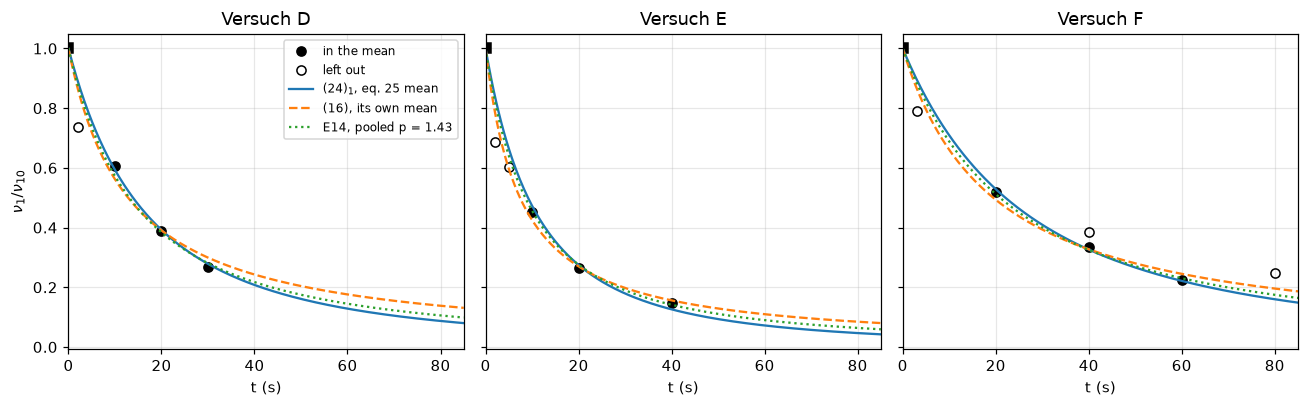

Under the other printed laws the same rows give $R/r$ = 1.84, 4.61, 3.58 by (16), 3.67, 9.23, 7.17 by (14) and 2.21, 4.41, 3.96 by (11), for D, E and F. Under (16), which the paper's (24)_1 replaces, D stays below 2.

**Drift of the per-row rate.** Relative slope of the per-row $1/T$ against $t$ over the rows in the mean (per s, $t$ value with one degree of freedom): under $(24)_1$ D +0.0041 (+3.9), E -0.0065 (-5.7), F -0.0012 (-0.9); under (16) D +0.0163 (+22.1), E +0.0052 (+1.9), F +0.0055 (+3.7). The rate rises with $t$ in 3 of 3 Versuche under (16) and in 1 of 3 under $(24)_1$; the smallest $|t|$ behind these signs is 1.87 and 0.90.

**Shape family.** Fitted per Versuch (one degree of freedom, indicative) $p$ = 2.93, 1.24, 1.80, with $R/r$ = 1.30, 3.94, 2.70. Pooled with one common $p$ and a $1/T$ per Versuch (5 degrees of freedom): $p$ = 1.43 ± 0.18, 2.4 standard errors from 1 and 3.2 from 2, against the two-sided 95 % quantile of $t$ at that many degrees of freedom, 2.57, with $R/r$ = 1.60, 3.57, 2.98. The direct comparison of the two printed laws on the nine rows (squared ln residuals, each law with its own fitted $1/T$, paired): $(24)_1$ minus (16) = -0.0010 ± 0.0018, $t$ = -0.57. The counts do not choose between (16) and $(24)_1$; the pooled fit lies between.

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
tt = np.linspace(0, 85, 300)
for ax, v in zip(axs, VS):
    d, m = DATA[v], used(v, C0)
    y = d["nu1"] / nu10(v, C0)
    ax.plot(d["t"][m], y[m], "ko", label="in the mean")
    ax.plot(d["t"][~m & (d["t"] > 0)], y[~m & (d["t"] > 0)], "ko", mfc="none", label="left out")
    ax.plot(0, 1, "ks")
    s24, s16 = rr_stats(v, C0)["invT"], rr_stats(v, C0, "16")["invT"]
    sp_ = M["_r3_pooled_s"][v]
    p_ = M["r3_p_pooled"]
    ax.plot(tt, 1 / (1 + s24 * tt) ** 2, "C0-", label="$(24)_1$, eq. 25 mean")
    ax.plot(tt, 1 / (1 + 2 * s16 * tt), "C1--", label="(16), its own mean")
    ax.plot(tt, (1 + 2 * sp_ * tt / p_) ** -p_, "C2:", label=f"E14, pooled p = {p_:.2f}")
    ax.set_xlim(0, 85)
    ax.set_title(f"Versuch {v}")
    ax.set_xlabel("t (s)")
axs[0].set_ylabel(r"$\nu_1/\nu_{10}$")
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
say("Under the other printed laws the same rows give $R/r$ = <<a:.2f>>, <<b:.2f>>, <<c:.2f>> by (16), "
    "<<d:.2f>>, <<e:.2f>>, <<f:.2f>> by (14) and <<g:.2f>>, <<h:.2f>>, <<i:.2f>> by (11), for D, E and F. Under (16), "
    "which the paper's (24)_1 replaces, D stays below 2.\n\n"
    "**Drift of the per-row rate.** Relative slope of the per-row $1/T$ against $t$ over the rows in the mean "
    "(per s, $t$ value with one degree of freedom): under $(24)_1$ D <<td:+.4f>> (<<ttd:+.1f>>), E <<te:+.4f>> "
    "(<<tte:+.1f>>), F <<tf:+.4f>> (<<ttf:+.1f>>); under (16) D <<ud:+.4f>> (<<utd:+.1f>>), E <<ue:+.4f>> "
    "(<<ute:+.1f>>), F <<uf:+.4f>> (<<utf:+.1f>>). The rate rises with $t$ in <<n16:d>> of 3 Versuche under (16) and "
    "in <<n24:d>> of 3 under $(24)_1$; the smallest $|t|$ behind these signs is <<m16:.2f>> and <<m24:.2f>>.\n\n"
    "**Shape family.** Fitted per Versuch (one degree of freedom, indicative) $p$ = <<pd:.2f>>, <<pe:.2f>>, "
    "<<pf:.2f>>, with $R/r$ = <<qd:.2f>>, <<qe:.2f>>, <<qf:.2f>>. Pooled with one common $p$ and a $1/T$ per Versuch "
    "(<<dof:d>> degrees of freedom): $p$ = <<p:.2f>> ± <<ps:.2f>>, <<t1:.1f>> standard errors from 1 and <<t2:.1f>> "
    "from 2, against the two-sided 95 % quantile of $t$ at that many degrees of freedom, <<tq:.2f>>, with $R/r$ = <<rd:.2f>>, <<re:.2f>>, <<rf:.2f>>. The direct comparison of the two printed laws on the nine rows "
    "(squared ln residuals, each law with its own fitted $1/T$, paired): $(24)_1$ minus (16) = <<pd2:.4f>> ± "
    "<<pse:.4f>>, $t$ = <<pt:.2f>>. The counts do not choose between (16) and $(24)_1$; the pooled fit lies between.",
    a=M["r3_D_Rr_eq16"], b=M["r3_E_Rr_eq16"], c=M["r3_F_Rr_eq16"], d=M["r3_D_Rr_eq14"], e=M["r3_E_Rr_eq14"],
    f=M["r3_F_Rr_eq14"], g=M["r3_D_Rr_eq11"], h=M["r3_E_Rr_eq11"], i=M["r3_F_Rr_eq11"],
    td=M["r3_D_trend_eq24"], te=M["r3_E_trend_eq24"], tf=M["r3_F_trend_eq24"], ttd=M["r3_D_trend_t_eq24"],
    tte=M["r3_E_trend_t_eq24"], ttf=M["r3_F_trend_t_eq24"], ud=M["r3_D_trend_eq16"], ue=M["r3_E_trend_eq16"],
    uf=M["r3_F_trend_eq16"], utd=M["r3_D_trend_t_eq16"], ute=M["r3_E_trend_t_eq16"], utf=M["r3_F_trend_t_eq16"],
    n16=M["r3_n_rising_eq16"], n24=M["r3_n_rising_eq24"], m16=M["r3_n_rising_eq16__margin"],
    m24=M["r3_n_rising_eq24__margin"], pd=M["r3_D_p"], pe=M["r3_E_p"], pf=M["r3_F_p"], qd=M["r3_D_Rr_at_p"],
    qe=M["r3_E_Rr_at_p"], qf=M["r3_F_Rr_at_p"], p=M["r3_p_pooled"], ps=M["r3_p_pooled_se"],
    t1=M["r3_p_pooled_t1"], t2=M["r3_p_pooled_t2"], dof=M["r3_pooled_dof"], tq=M["r3_p_pooled_t_crit"], rd=M["r3_D_Rr_pooled_p"], re=M["r3_E_Rr_pooled_p"],
    rf=M["r3_F_Rr_pooled_p"], pd2=M["r3_paired_d"], pse=M["r3_paired_se"], pt=M["r3_paired_t"])
if any(M[f"_r3_{v}_p_at_bound"] for v in VS) or M["_r3_pooled_at_bound"]:
    raise ValueError("a shape fit stopped at a bound of p")

### R4. The rows the paper left out

The 2, 3 and 5 s rows give a rate two to three times the later one. The paper weighs
two explanations (p. 150): the transient term it dropped on p. 141, which it rejects,
and a delay before coagulation starts, which it adopts without correcting any row.

In [13]:
say("**(a) The transient.** With $D = 1/(4\\pi rC)$ and the Versuch's own $R/r$, $R^2/D$ = <<a:.1e>> s (D), "
    "<<b:.1e>> s (E) and <<c:.1e>> s (F), against the paper's \"ca. $10^{-3}$ bis $10^{-4}$ Sekunden\" (p. 141); "
    "$4\\pi R^3\\nu_0$, which the footnote of p. 141 needs small, is at most <<d:.1e>>. Kept in the kernel (E15, "
    "pair diffusivity $2D$), the transient shifts each early row by <<lo:pct2>> to <<hi:pct1>> of the shift that "
    "row needs to lie on the accepted $1/T$ (<<n:d>> rows; E at 2 s: <<de:.4f>> s of <<ne:.2f>> s). The paper's "
    "rejection of this explanation holds.\n\n"
    "**(b) The delay.** A straight line $\\sqrt{\\nu_{10}/\\nu_1} - 1 = (t + t_0)/T$ through the three rows in the "
    "mean gives $t_0$ = <<td:.2f>> ± <<sd:.3f>> s (D), <<te:.2f>> ± <<se:.2f>> s (E) and <<tf:.2f>> ± <<sf:.2f>> s (F), "
    "one degree of freedom each. The early rows would need $t_0$ = <<id:.2f>> s (D, 2 s), <<ie2:.2f>> and <<ie5:.2f>> s "
    "(E, 2 and 5 s) and <<if_:.2f>> s (F, 3 s) on that line. Rule, with the two-sided 95 % quantile of $t$ at the fit's "
    "degrees of freedom (<<tc:.2f>>) in place of 2: undetermined when $|t_0|$ is below that many standard errors "
    "(it is <<z0d:.1f>> (D), <<z0e:.2f>> (E), <<z0f:.2f>> (F)), consistent when every early row lies within that "
    "many standard errors of $t_0$ (the largest distance is <<zid:.1f>> (D), <<zie:.1f>> (E), <<zif:.1f>> (F)), "
    "inconsistent otherwise. Verdicts: D <<vd>>, E <<ve>>, F <<vf>>. D's accepted rows fall on a line with a negative intercept ($t_0$ < 0 above), so a delay "
    "cannot explain its 2 s row; for E and F the three rows do not fix $t_0$. With the delay fitted, $R/r$ = "
    "<<rd:.2f>>, <<re:.2f>>, <<rf:.2f>>. The delay is inferred under $(24)_1$, not measured.",
    a=M["r4_D_R2_D"], b=M["r4_E_R2_D"], c=M["r4_F_R2_D"], d=max(M[f"_r4_{v}_4piR3nu0"] for v in VS), tc=M["r4_t_crit"],
    z0d=M["r4_D_t0_z"], z0e=M["r4_E_t0_z"], z0f=M["r4_F_t0_z"], zid=M["r4_D_t0_implied_z_max"],
    zie=M["r4_E_t0_implied_z_max"], zif=M["r4_F_t0_implied_z_max"],
    lo=M["r4_transient_ratio_min"], hi=M["r4_transient_ratio_max"], n=M["r4_n_early"], de=M["r4_E_delta_t2"],
    ne=M["r4_E_need_t2"], td=M["r4_D_t0"], sd=M["r4_D_t0_se"], te=M["r4_E_t0"], se=M["r4_E_t0_se"],
    tf=M["r4_F_t0"], sf=M["r4_F_t0_se"], id=M["r4_D_t0_implied_t2"], ie2=M["r4_E_t0_implied_t2"],
    ie5=M["r4_E_t0_implied_t5"], if_=M["r4_F_t0_implied_t3"], vd=M["r4_D_delay_verdict"],
    ve=M["r4_E_delay_verdict"], vf=M["r4_F_delay_verdict"], rd=M["r4_D_Rr_delay"], re=M["r4_E_Rr_delay"],
    rf=M["r4_F_Rr_delay"])

**(a) The transient.** With $D = 1/(4\pi rC)$ and the Versuch's own $R/r$, $R^2/D$ = 2.2e-05 s (D), 6.4e-04 s (E) and 4.6e-04 s (F), against the paper's "ca. $10^{-3}$ bis $10^{-4}$ Sekunden" (p. 141); $4\pi R^3\nu_0$, which the footnote of p. 141 needs small, is at most 2.9e-05. Kept in the kernel (E15, pair diffusivity $2D$), the transient shifts each early row by 0.15 % to 3.5 % of the shift that row needs to lie on the accepted $1/T$ (4 rows; E at 2 s: 0.0286 s of 2.58 s). The paper's rejection of this explanation holds.

**(b) The delay.** A straight line $\sqrt{\nu_{10}/\nu_1} - 1 = (t + t_0)/T$ through the three rows in the mean gives $t_0$ = -1.16 ± 0.047 s (D), 4.30 ± 2.63 s (E) and 1.00 ± 1.77 s (F), one degree of freedom each. The early rows would need $t_0$ = 3.16 s (D, 2 s), 3.67 and 2.82 s (E, 2 and 5 s) and 3.82 s (F, 3 s) on that line. Rule, with the two-sided 95 % quantile of $t$ at the fit's degrees of freedom (12.71) in place of 2: undetermined when $|t_0|$ is below that many standard errors (it is 24.4 (D), 1.64 (E), 0.57 (F)), consistent when every early row lies within that many standard errors of $t_0$ (the largest distance is 91.1 (D), 0.6 (E), 1.6 (F)), inconsistent otherwise. Verdicts: D inconsistent, E undetermined, F undetermined. D's accepted rows fall on a line with a negative intercept ($t_0$ < 0 above), so a delay cannot explain its 2 s row; for E and F the three rows do not fix $t_0$. With the delay fitted, $R/r$ = 1.51, 2.50, 2.53. The delay is inferred under $(24)_1$, not measured.

### R5. Kernel (18) against the constant kernel (19)

The paper sets every pair constant to its equal-size value and argues that "die
Grössenordnung des betreffenden Ausdrucks auch bei einigermassen verschiedenem
Radienverhältnis die gleiche bleibt" (p. 145: the order of magnitude of the
expression stays the same even for somewhat different radii). E17 keeps kernel (18)
with compact aggregates (A3).

In [14]:
say("With kernel (18), $\\nu_1$ is <<a:.4f>> and <<b:.4f>> times its (24) value at $\\tau$ = 1 and 2, and "
    "$\\sum\\nu$ <<c:.4f>> times (23) at $\\tau$ = 2: larger aggregates collide faster, so the singles fall a little "
    "faster. Inverting the kernel-(18) curve row by row (`find_roots` on the Hermite interpolant of the march) "
    "moves $R/r$ by <<d:+pct2>> (D), <<e:+pct2>> (E) and <<f:+pct2>> (F), to <<rd:.3f>>, <<re:.3f>>, <<rf:.3f>>. "
    "Each shift is below the Versuch's standard error of R2 (<<nw:d>> of 3; the largest is <<mx:.2f>> of it): the "
    "paper's simplification holds in the sense it states.",
    a=M["r5_nu1_ratio_tau1"], b=M["r5_nu1_ratio_tau2"], c=M["r5_sum_ratio_tau2"], d=M["r5_D_shift"],
    e=M["r5_E_shift"], f=M["r5_F_shift"], rd=M["r5_D_Rr"], re=M["r5_E_Rr"], rf=M["r5_F_Rr"],
    nw=M["r5_n_within_se"], mx=M["r5_shift_over_se_max"])

With kernel (18), $\nu_1$ is 0.9928 and 0.9793 times its (24) value at $\tau$ = 1 and 2, and $\sum\nu$ 0.9884 times (23) at $\tau$ = 2: larger aggregates collide faster, so the singles fall a little faster. Inverting the kernel-(18) curve row by row (`find_roots` on the Hermite interpolant of the march) moves $R/r$ by -0.43 % (D), -0.71 % (E) and -0.52 % (F), to 1.399, 3.077, 2.603. Each shift is below the Versuch's standard error of R2 (3 of 3; the largest is 0.26 of it): the paper's simplification holds in the sense it states.

### R6. R/r under every choice

Every choice of R2 to R5 applied alone, laws (11) and (14) excepted (stated below the
table); the vertical line is contact, $R/r = 2$, the bar the base value ± one standard
error of R2.

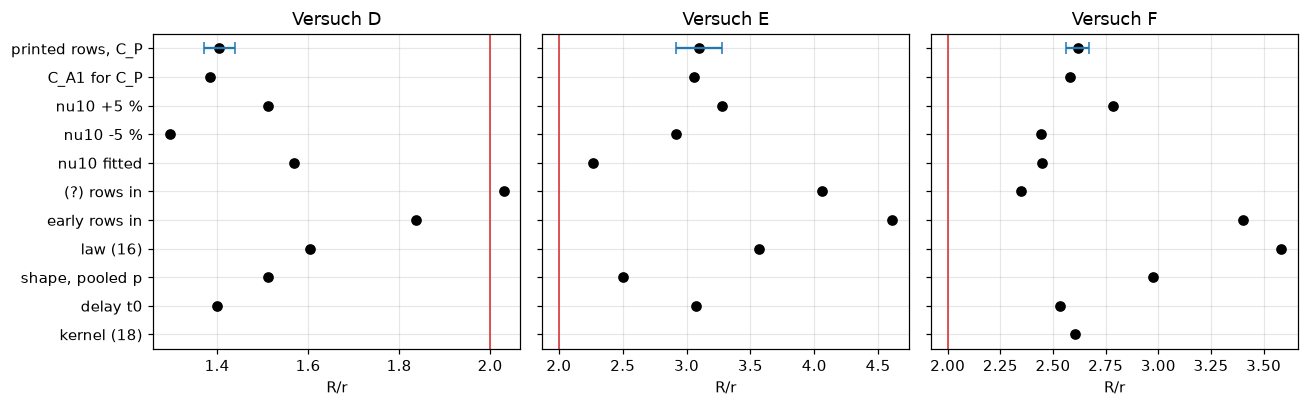

,D,E,F
"printed rows, C_P",1.405,3.099,2.617
C_A1 for C_P,1.385,3.056,2.580
nu10 +5 %,1.511,3.274,2.787
nu10 -5 %,1.297,2.920,2.443
nu10 fitted,1.569,2.268,2.448
(?) rows in,-,-,2.346
early rows in,2.030,4.061,3.401
law (16),1.836,4.613,3.584
"shape, pooled p",1.605,3.568,2.976
delay t0,1.512,2.502,2.533


Ranges over the choices kept: D 1.297 to 2.030, E 2.27 to 4.61, F 2.35 to 3.58, 1.2, 2.1 and 2.0 times each base value's distance from 2. Laws (11) and (14) are left out: they hold the nucleus fixed ($D$ for $D_1 + D_2$, p. 143) and give Versuch D 2.21 and 3.67. 1 of 3 ranges contain 2: D's, and among the choices kept only through its 2 s row: the 2, 3, 5 s rows in the mean give 2.030, 0.8 of the movement that rounding the counts can cause above 2, so the printed digits do not decide whether D's range reaches 2. 9 of D's 10 choices give values below 2. E (10 of 10 above 2) and F (11 of 11) lie above 2 in value. Each choice has its own mean, standard error and degrees of freedom (the row scatter, or the covariance of the fit that gives it), and 2 is tested against the two-sided 95 % quantile of $t$ at those degrees of freedom: 2 is excluded in 7 of E's 10 choices and 7 of F's 11, and in 19 of the 28 choices other than the base (the base: 3 of 3).

In [15]:
tab6 = M["_r6_table"]
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, v in zip(axs, VS):
    col = tab6[v].dropna()
    ax.plot(col.values, range(len(col)), "ko")
    ax.errorbar(M[f"r2_{v}_Rr"], 0, xerr=M[f"r2_{v}_se"], fmt="none", ecolor="C0", capsize=4)
    ax.axvline(2, color="C3", lw=1)
    ax.set_yticks(range(len(col)), col.index)
    ax.set_title(f"Versuch {v}")
    ax.set_xlabel("R/r")
axs[0].invert_yaxis()
plt.tight_layout()
plt.show()
display(tab6.map(lambda x: "-" if not np.isfinite(x) else f"{x:.3f}"))
say("Ranges over the choices kept: D <<dl:.3f>> to <<dh:.3f>>, E <<el:.2f>> to <<eh:.2f>>, F <<fl:.2f>> to <<fh:.2f>>, "
    "<<dr:.1f>>, <<er:.1f>> and <<fr:.1f>> times each base value's distance from 2. Laws (11) and (14) are left out: "
    "they hold the nucleus fixed ($D$ for $D_1 + D_2$, p. 143) and give Versuch D <<la:.2f>> and <<lb:.2f>>. "
    "<<n:d>> of 3 ranges contain 2: D's, and among the choices kept only through its 2 s row: the 2, 3, 5 s rows in the "
    "mean give <<de:.3f>>, <<dre:.1f>> of the movement that rounding the counts can cause above 2, so the printed "
    "digits do not decide whether D's range reaches 2. <<sd:d>> of D's <<cd:d>> choices give values below 2. E "
    "(<<se_:d>> of <<ce:d>> above 2) and F (<<sf:d>> of <<cf:d>>) lie above 2 in value. Each choice has its own "
    "mean, standard error and degrees of freedom (the row scatter, or the covariance of the fit that gives it), and "
    "2 is tested against the two-sided 95 % quantile of $t$ at those degrees of freedom: 2 is excluded in "
    "<<xe:d>> of E's <<ce:d>> choices and <<xf:d>> of F's <<cf:d>>, and in <<nk:d>> of the <<nt:d>> choices other "
    "than the base (the base: <<nx:d>> of 3).",
    dl=M["r6_D_lo"], dh=M["r6_D_hi"], el=M["r6_E_lo"], eh=M["r6_E_hi"], fl=M["r6_F_lo"], fh=M["r6_F_hi"],
    dr=M["r6_D_range_over_gap"], er=M["r6_E_range_over_gap"], fr=M["r6_F_range_over_gap"], n=M["r6_n_contain_2"],
    la=M["r3_D_Rr_eq11"], lb=M["r3_D_Rr_eq14"],
    de=tab6.loc["early rows in", "D"], dre=M["r6_D_early_gap_over_rounding"],
    sd=M["r6_D_n_same_side"], cd=M["r6_D_n_choices"], se_=M["r6_E_n_same_side"],
    ce=M["r6_E_n_choices"], sf=M["r6_F_n_same_side"], cf=M["r6_F_n_choices"],
    xe=M["r6_E_n_excluding_2"], xf=M["r6_F_n_excluding_2"], nk=M["r6_n_other_excluding_2"],
    nt=M["r6_n_other_choices"], nx=M["r2_n_excluding_2"])

## Validation

### V1. The closed forms, and Figure 1 redrawn

Eq. 24 is substituted into eq. 22 symbolically; the series of (24) is summed against
(23) and against $\nu_0$; the maxima of $\nu_k$ are roots of $d\nu_k/d\tau$ with the
poles multiplied out, $(k-1)(1+\tau) - (k+1)\tau$, by `find_roots`, set against the
paper's $t = (k-1)T/2$ and $4\nu_0(k-1)^{k-1}/(k+1)^{k+1}$ (p. 146).

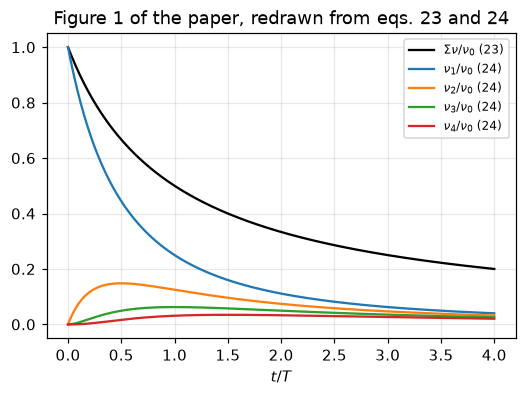

Eq. 24 satisfies eq. 22 for 6 of 6 sizes ($k$ = 1 to 6, sympy). The series against (23), with its closed-form tail, and $\sum k\nu_k$ against E13 differ by at most 3.3e-16 and 3.3e-16 (bound 1e-14) at $\tau$ = 0.5, 1, 2, 5. The maxima for $k$ = 2 to 6 lie at $(k-1)/2$ within 2.2e-16 and equal the printed maximum within 4.4e-16 (relative); $\nu_1(T)/\nu_0$ = 0.2500, $\nu_2$ peaks at $\tau$ = 0.5000 with 0.148148 = 4/27 and $\nu_5$ at 2.0000 with 0.021948. The initial slopes of (11), (14), (16) and $(24)_1$ are $-1$, $-1$, $-2$, $-2$ in units of $1/T$ as stated (4 of 4, symbolic).

In [16]:
tau_ = np.linspace(0, 4, 400)
plt.figure(figsize=(5.5, 3.6))
plt.plot(tau_, 1 / (1 + tau_), "k-", label=r"$\Sigma\nu/\nu_0$ (23)")
for k in range(1, 5):
    plt.plot(tau_, n_k(k, tau_), label=rf"$\nu_{k}/\nu_0$ (24)")
plt.xlabel(r"$t/T$")
plt.legend(fontsize=8)
plt.title("Figure 1 of the paper, redrawn from eqs. 23 and 24")
plt.show()
say("Eq. 24 satisfies eq. 22 for <<a:d>> of 6 sizes ($k$ = 1 to 6, sympy). The series against (23), with its "
    "closed-form tail, and $\\sum k\\nu_k$ against E13 differ by at most <<s:.1e>> and <<m:.1e>> (bound 1e-14) at "
    "$\\tau$ = 0.5, 1, 2, 5. The maxima for $k$ = 2 to 6 lie at $(k-1)/2$ within <<g:.1e>> and equal the printed "
    "maximum within <<h:.1e>> (relative); $\\nu_1(T)/\\nu_0$ = <<n1:.4f>>, $\\nu_2$ peaks at $\\tau$ = <<t2:.4f>> with "
    "<<n2:.6f>> = 4/27 and $\\nu_5$ at <<t5:.4f>> with <<n5:.6f>>. The initial slopes of (11), (14), (16) and "
    "$(24)_1$ are $-1$, $-1$, $-2$, $-2$ in units of $1/T$ as stated (<<sl:d>> of 4, symbolic).",
    a=M["v1_eq24_in_eq22"], s=M["v1_sum_gap"], m=M["v1_mass_gap"], g=M["v1_argmax_gap"], h=M["v1_max_gap"],
    n1=M["v1_nu1_at_T"], t2=M["v1_tau_nu2_max"], n2=M["v1_nu2_max"], t5=M["v1_tau_nu5_max"], n5=M["v1_nu5_max"],
    sl=M["v1_initial_slopes_match"])

### V2. The march of E17

RK4 on 64, 128, 256, 512 and 1024 steps over $0 \le \tau \le 2$, on every $\nu_k$
at $\tau$ = 1 and 2 and on $\sum\nu(2)$ (the largest difference over them). With
kernel (19) the march must meet (24); the round-off companion repeats the finest
march with the convolutions by FFT and exactly rounded sums; the truncation is checked at $K$ = 80, 120, 160; DOP853 is a second route.

In [17]:
say("Kernel (19): orders <<a:.4f>> to <<b:.4f>> (theory 4); the 1024-step values meet (24) within <<c:.1e>>, the "
    "extrapolated ones within <<d:.1e>>, and the Hermite interpolant meets $(24)_1$ at the <<nd:d>> data $\\tau$ "
    "within <<e:.1e>>. Kernel (18): orders <<f:.4f>> to <<g:.4f>>; the finest step difference <<h:.1e>> is <<r:.1e>> "
    "times the round-off companion (<<ro:.1e>>); the Richardson error estimate of the 1024-step values is <<est:.1e>>. "
    "Truncation: $\\nu_1(2)$ changes by at most <<tr:.1e>> from $K$ = 80 to 160. DOP853 (rtol 1e-13) agrees with the "
    "1024-step RK4 within <<dop:.1e>>.",
    a=M["v2_k19_orders_min"], b=M["v2_k19_orders_max"], c=M["v2_k19_finest_err"], d=M["v2_k19_extrap_err"],
    nd=sum(int(used(v, C0).sum()) for v in VS), e=M["v2_k19_data_tau_err"], f=M["v2_orders_min"],
    g=M["v2_orders_max"], h=M["v2_finest_diff"], r=M["v2_finest_over_roundoff"], ro=M["v2_roundoff_companion"],
    est=M["v2_rk4_error_estimate"], tr=M["v2_truncation_change"], dop=M["v2_dop853_gap"])

Kernel (19): orders 3.9949 to 3.9997 (theory 4); the 1024-step values meet (24) within 2.8e-13, the extrapolated ones within 1.1e-16, and the Hermite interpolant meets $(24)_1$ at the 9 data $\tau$ within 2.5e-13. Kernel (18): orders 3.9944 to 3.9995; the finest step difference 4.2e-12 is 6.1e+05 times the round-off companion (6.9e-18); the Richardson error estimate of the 1024-step values is 2.8e-13. Truncation: $\nu_1(2)$ changes by at most 9.7e-17 from $K$ = 80 to 160. DOP853 (rtol 1e-13) agrees with the 1024-step RK4 within 3.0e-13.

### V3. Eq. 29 and Figure 2 redrawn

The bracket of E13 is checked against the direct sum of (24) (M1), and the large-$k$
limit against eq. 29 at $x = t/(kT)$ (M2).

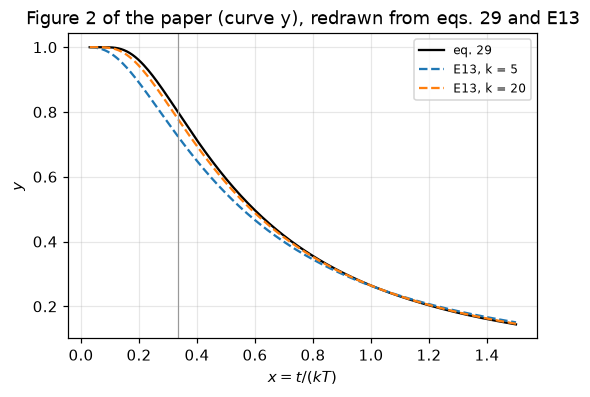

At $k$ = 50, $\tau$ = 20 the corrected E13 gives 0.705168, the direct sum differs by 7.8e-16 (bound 1e-13); the printed bracket gives -3.2398, below zero, and tends to $-k$. Eq. 29 at $x$ = 1/3 is 0.800852, and E13 at $k$ = 1000 there 0.800404 (difference -4.5e-04, the finite-$k$ correction). The inflection of eq. 29, by `find_roots`, is at 0.333333 = 1/3 as stated (p. 157). Read with $x = t/T$, E13 at large $k$ does not approach eq. 29 at all.

In [18]:
xx = np.linspace(0.03, 1.5, 300)
plt.figure(figsize=(5.5, 3.6))
plt.plot(xx, [y29(x) for x in xx], "k-", label="eq. 29")
for k in (5, 20):
    plt.plot(xx, y_k_at_x(k, xx, C0), "--", label=f"E13, k = {k}")
plt.axvline(1 / 3, color="0.6", lw=0.8)
plt.xlabel(r"$x = t/(kT)$")
plt.ylabel("$y$")
plt.legend(fontsize=8)
plt.title("Figure 2 of the paper (curve y), redrawn from eqs. 29 and E13")
plt.show()
say("At $k$ = 50, $\\tau$ = 20 the corrected E13 gives <<a:.6f>>, the direct sum differs by <<g:.1e>> (bound "
    "1e-13); the printed bracket gives <<p:.4f>>, below zero, and tends to $-k$. Eq. 29 at $x$ = 1/3 is "
    "<<y:.6f>>, and E13 at $k$ = 1000 there <<yk:.6f>> (difference <<d:.1e>>, the finite-$k$ correction). The "
    "inflection of eq. 29, by `find_roots`, is at <<i:.6f>> = 1/3 as stated (p. 157). Read with $x = t/T$, E13 at "
    "large $k$ does not approach eq. 29 at all.",
    a=M["v3_y_corrected"], g=M["v3_y_identity_gap"], p=M["v3_y_printed"], y=M["_v3_y29_third"],
    yk=M["v3_y_k1000_third"], d=M["v3_limit_gap_k1000"], i=M["_v3_inflection"])

### V4. The paper's own arithmetic with the implied constant

Eq. 28 (p. 156) gives the ratio $\beta$ of shear to Brownian coagulation,
$\beta = 4r^3\mu(\partial u/\partial z)/(H\Theta/N) = \tfrac83 C r^3$ at
$\partial u/\partial z$ = 1/s and $R = 2r$: "so würde sich $\beta$ von der
Grössenordnung $10^{-5}$ ergeben, aber schon für $r = 1\,\mu$ würde $\beta = 1$
folgen". Eq. 27 with $R = 2r$ gives $T = C/(2\nu_0)$; p. 166 states that $T$ would be
one second "bereits bei einer Teilchenzahl $\nu_0 = \tfrac13\cdot10^{-12} N$, d. i. für
$\tfrac13\cdot10^{-9}$ normale wässerige Lösung".

In [19]:
say("With $C_P$: $\\beta$ = <<a:.2e>> at $r$ = 2.4e-6 cm (<<ar:.2f>> times the stated order $10^{-5}$) and "
    "<<b:.3f>> at 1 micron (stated 1). $\\nu_0$ for $T$ = 1 s is <<n:.3e>> per cm³, <<nr:.3f>> times the stated "
    "$\\tfrac13\\cdot10^{-12}N$ (with today's Avogadro constant), and the same <<cr:.3f>> as a concentration. The paper's "
    "own arithmetic is consistent with the constant its tables imply.",
    a=M["v4_beta_small"], ar=M["v4_beta_small_over_stated"], b=M["v4_beta_large"], n=M["v4_nu0_T1s"],
    nr=M["v4_nu0_T1s_over_stated"], cr=M["v4_normal_T1s_over_stated"])

With $C_P$: $\beta$ = 1.39e-05 at $r$ = 2.4e-6 cm (1.39 times the stated order $10^{-5}$) and 1.004 at 1 micron (stated 1). $\nu_0$ for $T$ = 1 s is 1.883e+11 per cm³, 0.938 times the stated $\tfrac13\cdot10^{-12}N$ (with today's Avogadro constant), and the same 0.938 as a concentration. The paper's own arithmetic is consistent with the constant its tables imply.

### V5. The check values

`data/check_values.csv` holds 55 quantities computed by a second route at the test
condition (Versuch E): eq. 25 per row, the means, $C$, $R/r$ under each law, the delay,
the shape fit, the transient, eqs. 27 to 29, the maxima and the kernel-(18) march.

In [20]:
say("The page's functions reproduce all <<c:d>> check values; worst relative deviation <<w:.1e>> (the shape "
    "exponent, rtol 1e-6; every other row within its rtol of 1e-11 or 1e-9).",
    c=len(CHECK_DEV), w=max(abs(v) for v in CHECK_DEV.values()))

The page's functions reproduce all 55 check values; worst relative deviation 2.3e-09 (the shape exponent, rtol 1e-6; every other row within its rtol of 1e-11 or 1e-9).

## Finding

The numbers above, set against each Versuch's own scatter.

In [21]:
say("**How precisely the counts fix $R/r$.** On the scatter of its three accepted rows, each Versuch fixes $R/r$ "
    "to <<rd:pct1>>, <<re:pct1>> and <<rf:pct1>> (one standard error): <<d:.3f>> ± <<sd:.3f>> (D), <<e:.2f>> ± <<se:.2f>> (E), <<f:.3f>> ± <<sf:.3f>> (F). On that "
    "scatter alone, 2 is excluded in <<nx:d>> of 3 Versuche ($t$ = <<td:.1f>>, <<te:.2f>>, <<tf:.1f>>, two degrees of "
    "freedom; it leaves out the shared $t = 0$ count, and ±5 % on it moves $R/r$ by ±<<sd5:pct1>>, ±<<se5:pct1>> and "
    "±<<sf5:pct1>>), and the three are not one value (F = <<F:.0f>>).\n\n"
    "**What the choices do.** Replacing the paper's choices by the alternatives of R2 to R5 moves $R/r$ by more than its scatter: over the conversion "
    "law, the $t = 0$ count, the excluded rows, the delay, the kernel and the constant $C$, D runs from "
    "<<dl:.2f>> to <<dh:.2f>>, E from <<el:.2f>> to <<eh:.2f>>, F from <<fl:.2f>> to <<fh:.2f>>. <<n:d>> of 3 "
    "ranges contain 2, D's, and among the choices kept only by readmitting the 2 s row the paper rejects, by less than "
    "the rounding of the counts can move it; E and F lie above 2 in value under every choice (<<ne:d>> of <<ce:d>>, "
    "<<nf:d>> of <<cf:d>>), and 2 is excluded on their own standard error in <<xe:d>> of <<ce:d>> and <<xf:d>> of "
    "<<cf:d>>.\n\n"
    "**The reading.** Point IV is a statement of order, and p. 151 itself reports $R/r$ from <<pl:.2f>> to <<ph:.2f>>. "
    "Across the choices the counts put $R/r$ between <<lo:.2f>> and <<hi:.2f>>, so the reading holds. Contact as a "
    "sharp value is a separate question: on each choice's own standard error, 2 is excluded under the paper's "
    "conversion in <<nx:d>> of 3 Versuche and under <<nk:d>> of the <<nt:d>> other choices, on both sides of it. D lies below 2 under <<ns:d>> of its "
    "<<nc:d>> choices, which the theory does not allow ($R/r = 2$ is contact, p. 151; it would need $\\nu_0$ or $C$ "
    "off by a factor <<fd:.2f>>). The page "
    "names no cause for D's low value; the paper leaves it open too. Three short series that Zsigmondy called "
    "preliminary, with no counting error printed, neither validate nor refute the theory.",
    d=M["r2_D_Rr"], sd=M["r2_D_se"], e=M["r2_E_Rr"], se=M["r2_E_se"], f=M["r2_F_Rr"], sf=M["r2_F_se"],
    td=M["r2_D_t2"], te=M["r2_E_t2"], tf=M["r2_F_t2"], F=M["r2_anova_F"], dl=M["r6_D_lo"], dh=M["r6_D_hi"],
    el=M["r6_E_lo"], eh=M["r6_E_hi"], fl=M["r6_F_lo"], fh=M["r6_F_hi"], n=M["r6_n_contain_2"],
    xe=M["r6_E_n_excluding_2"], xf=M["r6_F_n_excluding_2"], nk=M["r6_n_other_excluding_2"],
    nt=M["r6_n_other_choices"], pl=min(number(DATA[v]["Rr_s"]) for v in VS),
    ph=max(number(DATA[v]["Rr_s"]) for v in VS), sd5=M["r2_D_nu10_halfspan"], se5=M["r2_E_nu10_halfspan"],
    sf5=M["r2_F_nu10_halfspan"], lo=M["r6_all_lo"], hi=M["r6_all_hi"], fd=1 / M["r2_D_nu0_factor"],
    nx=M["r2_n_excluding_2"],
    ns=M["r6_D_n_same_side"], nc=M["r6_D_n_choices"], ne=M["r6_E_n_same_side"], ce=M["r6_E_n_choices"],
    nf=M["r6_F_n_same_side"], cf=M["r6_F_n_choices"], rd=M["r2_D_se"] / M["r2_D_Rr"],
    re=M["r2_E_se"] / M["r2_E_Rr"], rf=M["r2_F_se"] / M["r2_F_Rr"])

**How precisely the counts fix $R/r$.** On the scatter of its three accepted rows, each Versuch fixes $R/r$ to 2.4 %, 5.9 % and 2.0 % (one standard error): 1.405 ± 0.034 (D), 3.10 ± 0.18 (E), 2.617 ± 0.053 (F). On that scatter alone, 2 is excluded in 3 of 3 Versuche ($t$ = -17.3, 6.05, 11.6, two degrees of freedom; it leaves out the shared $t = 0$ count, and ±5 % on it moves $R/r$ by ±7.6 %, ±5.7 % and ±6.6 %), and the three are not one value (F = 111).

**What the choices do.** Replacing the paper's choices by the alternatives of R2 to R5 moves $R/r$ by more than its scatter: over the conversion law, the $t = 0$ count, the excluded rows, the delay, the kernel and the constant $C$, D runs from 1.30 to 2.03, E from 2.27 to 4.61, F from 2.35 to 3.58. 1 of 3 ranges contain 2, D's, and among the choices kept only by readmitting the 2 s row the paper rejects, by less than the rounding of the counts can move it; E and F lie above 2 in value under every choice (10 of 10, 11 of 11), and 2 is excluded on their own standard error in 7 of 10 and 7 of 11.

**The reading.** Point IV is a statement of order, and p. 151 itself reports $R/r$ from 1.40 to 3.12. Across the choices the counts put $R/r$ between 1.30 and 4.61, so the reading holds. Contact as a sharp value is a separate question: on each choice's own standard error, 2 is excluded under the paper's conversion in 3 of 3 Versuche and under 19 of the 28 other choices, on both sides of it. D lies below 2 under 9 of its 10 choices, which the theory does not allow ($R/r = 2$ is contact, p. 151; it would need $\nu_0$ or $C$ off by a factor 1.42). The page names no cause for D's low value; the paper leaves it open too. Three short series that Zsigmondy called preliminary, with no counting error printed, neither validate nor refute the theory.

## What pymrm adds

Nothing to the kinetics: the page is closed forms and one small ODE system without a
spatial operator, and calls no pymrm operator and no Newton solve. pymrm contributes
two checks. `pymrm.checks.find_roots` brackets every root the page reports (the
maxima of $\nu_k$, the inflection of eq. 29, and the inversion of the kernel-(18)
curve at each count) and raises unless exactly one root lies in the scanned range.
`pymrm.checks.observed_orders` measures the order of the RK4 ladder and gives the
Richardson error estimate of the march. What the page adds to the paper is a set of
checks it does not print: its arithmetic in half-units, the constant $C$ its tables
imply, the scatter of each Versuch as a standard error, and the conversion choices
varied one at a time.

## Reuse

- `n_k`, `y_k` and `y29` are the closed forms of constant-kernel coagulation; `rhs`
  and `march` integrate the truncated Smoluchowski system for any kernel of the form
  $\tfrac12(2 + c_i/c_j + c_j/c_i)$, and a different `rhs` gives any other kernel.
- `inv_t_rows`, `rr_stats` and `shape_fit` turn a table of single-particle counts into
  a coagulation time and a capture radius. Quote the standard error over rows and the
  range over the conversion choices together: on these data the second is the larger.
- $R/r$ from counts needs $\mu$, $\Theta$ and Boltzmann's constant; the paper prints
  none, and the constant its tables imply differs from water at 20 C by the factor in
  R1.
- A population balance with growth or a size grid belongs to the J2 pages on the
  general population balance (J2.1), MSMPR (J2.2), the fixed-pivot method (J2.4) and
  QMOM (J2.5).

### The break table

Every non-structural number registered below has a row that moves it. Each row
injects one defect through the `Cfg` object (a law, a factor, a switch, or one
mistyped printed entry) and reruns the whole study; the claims it fails are counted.
A row under which the study raises records a crash, listed separately and not
counted as catching a claim. The control fails nothing.

In [22]:
RTOL = 1e-6
# Claims no row can move: identities named as such, and row counts of the printed tables.
STRUCTURAL = {"v1_initial_slopes_match": "eqs. 11, 14, 16 and 24_1 differentiated symbolically at t = 0",
              "v3_inflection_gap": "x^5 e^(1/x) y''(x) = 3x - 1 for eq. 29; bound: find_roots xtol",
              "v3_y29_gap": "eq. 29 at x = 1/3 against 1 - 4 exp(-3) by sympy",
              "r1_col_n": "entries of the printed 1/T columns", "r1_ber_n": "entries of the printed nu1 ber. columns",
              "r4_n_early": "rows at 2, 3 and 5 s in the printed tables",
              "r6_D_n_choices": "choices applied to D", "r6_E_n_choices": "choices applied to E",
              "r6_F_n_choices": "choices applied to F", "r6_n_other_choices": "choices other than the base, over D, E and F",
              "v3_y_printed": "the printed bracket of p. 156 evaluated at k 50, tau 20; the M1 row breaks the identity gap"}
BOUNDS = {"v1_sum_gap": (None, 1e-14, "identity", "eq. 23 against the series of eq. 24 plus its closed-form tail"),
          "v1_mass_gap": (None, 1e-14, "identity", "sum of k nu_k against E13 at K = 80"),
          "v1_argmax_gap": (None, 1e-10, "tolerance", "find_roots of the derivative against (k-1)/2, k = 2 to 6"),
          "v1_max_gap": (None, 1e-10, "tolerance", "nu_k at that root against 4(k-1)^(k-1)/(k+1)^(k+1), relative"),
          "v3_y_identity_gap": (None, 1e-13, "identity", "E13 against the direct sum at k 50, tau 20"),
          "v3_inflection_gap": (None, 1e-11, "tolerance", STRUCTURAL["v3_inflection_gap"]),
          "v3_y29_gap": (None, 1e-15, "identity", STRUCTURAL["v3_y29_gap"]),
          "v2_k19_extrap_err": (None, 1e-10, "tolerance", "stop rule: RK4 with kernel (19), extrapolated, against eq. 24"),
          "v2_k19_finest_err": (None, 1e-12, "tolerance", "RK4 at 1024 steps against eq. 24 at tau 1 and 2"),
          "v2_k19_data_tau_err": (None, 1e-12, "tolerance", "Hermite interpolant of the 1024-step march against eq. 24 at the data tau"),
          "v2_orders_min": (ORDER_RANGE[0], ORDER_RANGE[1], "theory", "RK4, kernel (18), steps 64 to 1024"),
          "v2_orders_max": (ORDER_RANGE[0], ORDER_RANGE[1], "theory", "RK4, kernel (18), steps 64 to 1024"),
          "v2_k19_orders_min": (ORDER_RANGE[0], ORDER_RANGE[1], "theory", "RK4, kernel (19), steps 64 to 1024"),
          "v2_k19_orders_max": (ORDER_RANGE[0], ORDER_RANGE[1], "theory", "RK4, kernel (19), steps 64 to 1024"),
          "v2_finest_over_roundoff": (1e3, None, "chosen", "finest step difference over the round-off companion (claims-design: 1e3)"),
          "v2_roundoff_companion": (None, 1e-14, "tolerance", "FFT convolutions and exactly rounded sums against direct ones"),
          "v2_rk4_error_estimate": (None, 1e-12, "tolerance", "Richardson estimate of the 1024-step values"),
          "v2_finest_diff": (None, 1e-11, "tolerance", "512 against 1024 steps"),
          "v2_truncation_change": (None, 1e-13, "tolerance", "nu1(2) at K 80, 120, 160"),
          "v2_dop853_gap": (None, 1e-12, "tolerance", "DOP853 rtol 1e-13 against RK4 1024 steps, kernel (18)")}
# Count margins: the counts are arithmetic on printed strings, exact up to floating
# point (1e-12); the margins of fitted signs and verdicts are in standard errors.
COUNTS = {"r1_col_n_within": 1e-4, "r1_D_col_n_within": 1e-4, "r1_E_col_n_within": 1e-4,
          "r1_F_col_n_within": 1e-4, "r1_ber_n_within": 1e-4, "r1_n_reachable": 1e-4,
          "r6_E_n_excluding_2": 0.01, "r6_F_n_excluding_2": 0.01, "r6_n_other_excluding_2": 0.01, "r3_n_rising_eq16": 0.5, "r3_n_rising_eq24": 0.5,
          "r6_n_contain_2": 0.005, "r6_D_n_same_side": 0.005, "r6_E_n_same_side": 0.005,
          "r6_F_n_same_side": 0.005, "r2_n_excluding_2": 0.05, "r5_n_within_se": 0.05, "r4_D_delay_verdict": 0.05, "r4_E_delay_verdict": 0.05, "r4_F_delay_verdict": 0.05}
EXACT = {"v1_eq24_in_eq22", "r3_pooled_dof", "r1_D_ber_n_within", "r1_E_ber_n_within", "r1_F_ber_n_within"}


def register(M):
    """Register every reported number with its kind."""
    for name, v in M.items():
        if name.startswith("_") or name.endswith("__margin"):
            continue
        if name in BOUNDS:
            lo, hi, basis, note = BOUNDS[name]
            claims.bound(name, v, min=lo, max=hi, basis=basis, structural=name in STRUCTURAL, note=note)
        elif name in STRUCTURAL:
            claims.exact(name, v, structural=True, note=STRUCTURAL[name])
        elif name in COUNTS:
            claims.exact(name, v, margin=M[name + "__margin"], min_margin=COUNTS[name])
        elif name in EXACT:
            claims.exact(name, v)
        else:
            claims.value(name, v, rtol=RTOL)


register(M)

In [23]:
def printed_row(g, item, at, new):
    """A break row that mistypes one printed entry (the first match) and rebuilds the data."""
    pn = PN.copy()
    i = pn.index[(pn.group == g) & (pn.item == item) & (pn["at"] == at)][0]
    old = pn.at[i, "printed"]
    pn.at[i, "printed"] = new
    return f"{g} {item}{' at ' + at + ' s' if at else ''} {old} -> {new}", replace(C0, data={**DATA, g: versuch(g, pn)})


DEFECTS = [
    ("eq. 25 without the square root (law 16)", replace(C0, law="16")),
    ("nu10 5 % high", replace(C0, nu10_factor=1.05)),
    ("t read in minutes", replace(C0, t_scale=60.0)),
    ("C_A1 (water 20 C) for C_P", replace(C0, c_choice="A1")),
    ("F's (?) rows in the mean", replace(C0, doubtful_in=True)),
    ("the 2, 3, 5 s rows in the mean", replace(C0, early_in=True)),
    ("transient with D for 2D", replace(C0, d12_factor=1.0)),
    ("kernel (19) for (18)", replace(C0, c_exp=0.0)),
    ("Euler for RK4", replace(C0, stepper="euler")),
    ("truncation K = 20", replace(C0, k_trunc=20)),
    ("E13 bracket as printed (M1)", replace(C0, y_form="printed")),
    ("x = t/T in eq. 29 (M2)", replace(C0, x29="t/T")),
    ("eq. 24 denominator (1 + tau)^k", replace(C0, nk_den=0)),
    ("RK4 ladder 8 times finer", replace(C0, ladder_factor=8)),
    ("march in single precision", replace(C0, dtype="float32")),
    printed_row("E", "mean_invT", "", "0.0466"),
    printed_row("D", "Rr", "", "1.50"),
    printed_row("F", "nu0", "", "0.29e10"),
    printed_row("D", "r", "", "14.4e-7"),
    printed_row("D", "invT", "10", "0.0296"),
    printed_row("F", "nu1_ber", "60", "0.46"),
    printed_row("F", "nu1", "40", "0.70"),
    printed_row("F", "nu1", "20", "1.10"),
    printed_row("E", "invT", "20", "0.0485"),
    printed_row("E", "nu1", "0", "1.977"),
]
CONTROLS = [("control: clean rerun", C0)]
claims.define_rows([r_ for r_, _ in CONTROLS + DEFECTS])
BREAK, CRASH = [], set()   # CRASH: rows under which every claim came back without a number
for row, c_ in CONTROLS + DEFECTS:
    try:
        Mb = study(c_)
    except (ValueError, RuntimeError, np.linalg.LinAlgError) as e:
        print(f"{row}: {e}")
        Mb = {}
    for name in claims.metrics:
        x_ = Mb.get(name, np.nan)
        # a claim a row's study does not produce (absent, nan) is not a catch: only a crashed
        # row records nan, for every claim, and is listed apart
        if Mb and (x_ is None or (isinstance(x_, (float, np.floating)) and np.isnan(x_))):
            continue
        BREAK.append((row, name, claims.breaks(row, name, x_)))
    if not any(name in Mb for name in claims.metrics):
        CRASH.add(row)

In [24]:
# The break table: one line per row, with the claims it fails.
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
_bad = [r_ for r_ in by_row if r_.startswith("control") and any(by_row[r_])]
assert not _bad, f"a control row failed a claim: {_bad}"
print(f"{'injected defect':<52} {'claims failed':>13}")
for r_, cs in by_row.items():
    print(f"{r_[:52]:<52} {sum(cs):13d}")
_caught = {m_ for r_, m_, c_ in BREAK if c_ and r_ not in CRASH}   # a crash is not a moved claim
print(f"rows that only crash: {', '.join(sorted(CRASH)) or 'none'}")
_open = sorted(k_ for k_ in claims.metrics if k_ not in _caught
               and not claims.metrics[k_].get("structural"))
print(f"\n{len(by_row)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; open: {', '.join(_open) or 'none'}")

injected defect                                      claims failed
control: clean rerun                                             0
eq. 25 without the square root (law 16)                         61
nu10 5 % high                                                  134
t read in minutes                                              115
C_A1 (water 20 C) for C_P                                       71
F's (?) rows in the mean                                        57
the 2, 3, 5 s rows in the mean                                 143
transient with D for 2D                                          3
kernel (19) for (18)                                            10
Euler for RK4                                                   20
truncation K = 20                                               11
E13 bracket as printed (M1)                                      5
x = t/T in eq. 29 (M2)                                           2
eq. 24 denominator (1 + tau)^k                                

In [25]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for J2.6:
  r1_D_col_n_within            = 3                exact  exact, margin 0.69
  r1_D_mean                    = 0.029843         value  rtol 1e-06
  r1_D_mean_gap_half_units     = 1.1449           value  rtol 1e-06
  r1_D_mean_gap_over_rounding  = 0.14319          value  rtol 1e-06
  r1_D_rounding_movement       = 0.00039978       value  rtol 1e-06
  r1_D_ber_n_within            = 2                exact  exact
  r1_E_col_n_within            = 0                exact  exact, margin 0.341
  r1_E_mean                    = 0.045419         value  rtol 1e-06
  r1_E_mean_gap_half_units     = 3.6227           value  rtol 1e-06
  r1_E_mean_gap_over_rounding  = 0.29694          value  rtol 1e-06
  r1_E_rounding_movement       = 0.00061          value  rtol 1e-06
  r1_E_mean_of_printed_entries = 0.0456           value  rtol 1e-06
  r1_E_ber_n_within            = 5                exact  exact
  r1_F_col_n_within            = 3                exact  exact, margin 0.000817
  r1_F_mean 